# EDA bình luận YouTube về smartphone tại Việt Nam

**Đầu vào:** `data/clean_data.jsonl`, dữ liệu **đã qua tiền xử lý**: chuẩn hóa `text_norm`, gắn cờ `is_spam` / `spam_reasons`, nhận diện `is_vietnamese`, tách mệnh đề `clauses`. Notebook chỉ đọc, không sửa file.

Notebook này gộp hai notebook trước đây (`eda_smartphone_comments` và `Phan_tich_binh_luan_tong_hop`) thành một luồng:

| Phần | Nội dung |
|---|---|
| 1 | Thiết lập: thư viện, đường dẫn, bảng model → hãng |
| 2 | **Kiểm tra dữ liệu (một cell)**: schema, khóa, thời gian, cờ spam, mệnh đề; tạo cột phục vụ phân tích |
| 3 | EDA: thành phần, tương tác, thời gian, văn bản, từ vựng, khía cạnh, mệnh đề, tác giả |
| 4 | Executive Report theo `docs/EDA_requirement.md` (đọc bundle của dashboard) |
| 5 | Tóm tắt sinh tự động từ dữ liệu |

**Đã bỏ so với hai bản cũ:** các bước làm sạch, tách mệnh đề, lọc spam bằng luật (đã làm ở pipeline); gán nhãn cảm xúc bằng luật và replay cảnh báo (phần tham khảo, không thuộc EDA); các biểu đồ dùng số giả lập (`np.random`, F1/throughput gõ tay); các nhận xét chứa số liệu viết tay của dữ liệu thô.

**Phạm vi phân tích:** bình luận có `is_spam = False`. Chạy từ đầu đến cuối bằng *Run All*; notebook tự tìm `data/clean_data.jsonl` dù kernel đặt ở thư mục gốc repo hay `src/processing`.

## 1. Thiết lập

In [25]:
import json
import re
import unicodedata
import warnings
from collections import Counter
from itertools import chain
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown, Image


def find_in_repo(rel_path: str) -> Path:
    """Tìm rel_path tính từ thư mục hiện tại đi ngược lên hoặc xuống các subfolder, để chạy được ở root repo, workspace, hoặc src/processing."""
    candidates = [Path.cwd(), *Path.cwd().parents]
    try:
        candidates += [p for p in Path.cwd().iterdir() if p.is_dir()]
    except Exception:
        pass
    for base in candidates:
        candidate = base / rel_path
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"Không tìm thấy '{rel_path}' từ {Path.cwd()} trở lên. Đặt file vào <repo>/{rel_path}.")


# ------------------------------------------------------------------ cấu hình
DATA_PATH = find_in_repo("data/clean_data.jsonl")
REPORT_DIR = find_in_repo("src/serving/dashboard/eda_smartphone_outputs")
LOCAL_TZ = "Asia/Ho_Chi_Minh"   # published_at là UTC; người xem chủ yếu ở Việt Nam
MIN_N_MODEL = 300               # model ít bình luận hơn ngưỡng này không đưa vào biểu đồ so sánh
TOP_K = 20
SEED = 42

EXPECTED_COLUMNS = [
    "comment_id", "video_id", "parent_id", "parent_text", "model", "source", "text", "text_norm",
    "author_hash", "published_at", "like_count", "reply_count", "fetched_at", "ingested_at",
    "is_spam", "spam_reasons", "is_vietnamese", "clause_count", "clauses", "schema_version",
]

# mã model -> (tên hiển thị, hãng). Nhãn ghép "a|b" là video so sánh nhiều máy.
MODEL_INFO = {
    "ip6": ("iPhone 6", "Apple"), "ip7": ("iPhone 7", "Apple"),
    "ip8": ("iPhone 8", "Apple"), "ipx": ("iPhone X", "Apple"),
    "ip11pro": ("iPhone 11 Pro", "Apple"), "ip12prm": ("iPhone 12 Pro Max", "Apple"),
    "ip13prm": ("iPhone 13 Pro Max", "Apple"), "ip14prm": ("iPhone 14 Pro Max", "Apple"),
    "ip17prm": ("iPhone 17 Pro Max", "Apple"), "ip18prm": ("iPhone 18 Pro Max", "Apple"),
    "s7edge": ("Galaxy S7 Edge", "Samsung"), "s8": ("Galaxy S8", "Samsung"),
    "s9plus": ("Galaxy S9+", "Samsung"), "s21u": ("Galaxy S21 Ultra", "Samsung"),
    "s22u": ("Galaxy S22 Ultra", "Samsung"), "s23u": ("Galaxy S23 Ultra", "Samsung"),
    "s25u": ("Galaxy S25 Ultra", "Samsung"), "s26u": ("Galaxy S26 Ultra", "Samsung"),
    "note4": ("Galaxy Note 4", "Samsung"), "note5": ("Galaxy Note 5", "Samsung"),
    "note7fe": ("Galaxy Note FE", "Samsung"), "note8": ("Galaxy Note 8", "Samsung"),
    "note20u|notefive": ("Galaxy Note 20U / Note 5", "Samsung"),
    "galaxya54": ("Galaxy A54", "Samsung"), "a52": ("Galaxy A52", "Samsung"),
    "mi6": ("Xiaomi Mi 6", "Xiaomi"), "mi8": ("Xiaomi Mi 8", "Xiaomi"),
    "mi11": ("Xiaomi Mi 11", "Xiaomi"), "mi11ultra": ("Xiaomi Mi 11 Ultra", "Xiaomi"),
    "xiaomi12u": ("Xiaomi 12S Ultra", "Xiaomi"), "xiaomi13u": ("Xiaomi 13 Ultra", "Xiaomi"),
    "xiaomi14u": ("Xiaomi 14 Ultra", "Xiaomi"), "xiaomi15u": ("Xiaomi 15 Ultra", "Xiaomi"),
    "redminote10pro": ("Redmi Note 10 Pro", "Xiaomi"), "redminote13pro": ("Redmi Note 13 Pro", "Xiaomi"),
    "p40pro": ("Huawei P40 Pro", "Huawei"),
    "reno5": ("OPPO Reno5", "OPPO"), "findx3pro": ("OPPO Find X3 Pro", "OPPO"),
    "findx7u": ("OPPO Find X7 Ultra", "OPPO"), "oppofindX8p": ("OPPO Find X8 Pro", "OPPO"),
    "x90proplus": ("vivo X90 Pro+", "vivo"), "vivoX100p": ("vivo X100 Pro", "vivo"),
    "ip8|note8": ("iPhone 8 vs Note 8", "Đa hãng"),
    "ip6|note4": ("iPhone 6 vs Note 4", "Đa hãng"),
    "a52|redminote10pro": ("Galaxy A52 vs RN10 Pro", "Đa hãng"),
    "ip15prm": ("iPhone 15 Pro Max", "Apple"),
    "s5": ("Galaxy S5", "Samsung"),
    "s24u": ("Galaxy S24 Ultra", "Samsung"),
    "mi5": ("Xiaomi Mi 5", "Xiaomi"),
    "findx5pro": ("OPPO Find X5 Pro", "OPPO"),
    "realme8pro": ("Realme 8 Pro", "realme"),
}
BRAND_COLORS = {
    "Apple": "#5F6B7A", "Samsung": "#1428A0", "Xiaomi": "#FF6900", "Huawei": "#C8102E",
    "OPPO": "#1D9A6C", "vivo": "#6C5CE7", "realme": "#FFC107", "Đa hãng": "#9E9E9E", "Khác": "#C9C9C9",
}

# ------------------------------------------------------------------ hiển thị
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial", "sans-serif"], "axes.unicode_minus": False,
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")

# ------------------------------------------------------------------ hàm tiện ích
EMOJI_PAT = "[\U0001F000-\U0001FAFF\u2600-\u27BF\u2B50\u2B55\uFE0F\u200D]+"
EMOJI_RE = re.compile(EMOJI_PAT)
EMOJI_CHAR_RE = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF]")


def plot_label(s, maxlen=38):
    """Làm sạch chuỗi để đặt lên trục (font thường không có glyph emoji)."""
    s = EMOJI_RE.sub(lambda m: f"[emoji×{len(m.group())}]", str(s).replace("\n", " ").strip())
    s = s if s else "[trống]"
    return s if len(s) <= maxlen else s[: maxlen - 1] + "…"


def strip_accents_str(s: str) -> str:
    if not isinstance(s, str):
        return ""
    norm = unicodedata.normalize("NFD", s)
    clean = "".join(ch for ch in norm if unicodedata.category(ch) != "Mn")
    return clean.replace("đ", "d").replace("Đ", "D")


def strip_accents(s: pd.Series) -> pd.Series:
    """Bỏ dấu tiếng Việt (NFD, bỏ dấu kết hợp, đ→d). Hoạt động chuẩn xác trên mọi engine pandas/pyarrow."""
    return s.map(strip_accents_str)


def pct(x, d=1):
    return f"{x * 100:.{d}f}%"


def annotate_barh(ax, fmt="{:,.0f}", pad=0.015, fontsize=8):
    lo, hi = ax.get_xlim()
    span = hi - lo
    # Mở rộng nhẹ xlim bên phải để nhãn text không bị tràn ra ngoài biên
    ax.set_xlim(lo, hi + span * 0.18)
    for p in ax.patches:
        w = p.get_width()
        if np.isfinite(w) and w != 0:
            ax.text(w + np.sign(w) * span * pad, p.get_y() + p.get_height() / 2, fmt.format(w),
                    va="center", ha="left" if w > 0 else "right", fontsize=fontsize)


def gini(values) -> float:
    v = np.sort(np.asarray(values, dtype=float))
    if v.sum() == 0:
        return 0.0
    n = len(v)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(v) / (n * v.sum()))


def ccdf(s: pd.Series):
    """P(X >= x) với mỗi giá trị x phân biệt."""
    v = np.sort(s.dropna().to_numpy())
    uniq, first_idx = np.unique(v, return_index=True)
    return uniq, (len(v) - first_idx) / len(v)


LIKE_BINS, LIKE_LABELS = [-1, 0, 1, 2, 5, 10, 50, np.inf], ["0", "1", "2", "3–5", "6–10", "11–50", "51+"]
REPLY_BINS, REPLY_LABELS = [-1, 0, 1, 2, 5, 10, np.inf], ["0", "1", "2", "3–5", "6–10", "11+"]
print("Dữ liệu:", DATA_PATH.resolve())

Dữ liệu: F:\intro_data_science\repo-feature-eda-dashboard\data\clean_data.jsonl


## 2. Kiểm tra dữ liệu đã tiền xử lý

Dữ liệu đã được làm sạch ở pipeline nên phần này **chỉ kiểm tra lại, không sửa**: đọc file, đối chiếu schema, khóa, thời gian, tính nhất quán giữa `is_spam` và `spam_reasons`, `clause_count` và `clauses`. Cuối cell tạo `df` gồm các bình luận `is_spam = False` cùng các cột dẫn xuất phục vụ phân tích (giờ GMT+7, hãng, độ dài...).

Lưu ý: pipeline điền `reply_count = 0` cho các reply. Với reply, giá trị này nghĩa là *không áp dụng*, nên trong `df` nó được đặt lại thành `NaN` và mọi thống kê về số trả lời chỉ tính trên bình luận gốc.

In [26]:
# ---- đọc file (báo dòng lỗi thay vì dừng giữa chừng)
records, n_bad = [], 0
with DATA_PATH.open(encoding="utf-8") as fh:
    for line in fh:
        if not line.strip():
            continue
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError:
            n_bad += 1
raw = pd.DataFrame.from_records(records)
for c in ["published_at", "fetched_at", "ingested_at"]:
    raw[c] = pd.to_datetime(raw[c], utc=True, errors="coerce")

# ---- các phép kiểm tra
missing_cols = [c for c in EXPECTED_COLUMNS if c not in raw.columns]
is_rep = raw["parent_id"].notna()
valid = ~raw["is_spam"].astype(bool)
has_reasons = raw["spam_reasons"].map(lambda v: isinstance(v, list) and len(v) > 0)
clause_len = raw["clauses"].map(lambda v: len(v) if isinstance(v, list) else -1)
orphans = int((~raw.loc[is_rep, "parent_id"].isin(set(raw.loc[~is_rep, "comment_id"]))).sum())
future = int((raw["published_at"] > raw["fetched_at"]).sum())
blank_norm = int((raw.loc[valid, "text_norm"].fillna("").str.strip() == "").sum())
unmapped = sorted(set(raw["model"].dropna()) - set(MODEL_INFO))

checks = pd.DataFrame([
    ("Mọi dòng là JSON hợp lệ", n_bad == 0, f"{n_bad:,} dòng lỗi"),
    ("Đủ cột theo schema", not missing_cols, f"thiếu {missing_cols}" if missing_cols else f"{raw.shape[1]} cột"),
    ("comment_id không trùng", raw["comment_id"].is_unique, f"{int(raw['comment_id'].duplicated().sum()):,} trùng"),
    ("published_at đọc được", raw["published_at"].notna().all(), f"{int(raw['published_at'].isna().sum()):,} lỗi"),
    ("Không có bình luận 'từ tương lai' (published_at ≤ fetched_at)", future == 0, f"{future:,} vi phạm"),
    ("like_count ≥ 0", bool((raw["like_count"] >= 0).all()), ""),
    ("Reply trỏ tới bình luận gốc có trong file", orphans == 0, f"{orphans:,} reply mồ côi"),
    ("is_spam khớp với spam_reasons", bool((raw["is_spam"] == has_reasons).all()),
     f"{int((raw['is_spam'] != has_reasons).sum()):,} dòng lệch"),
    ("Bình luận hợp lệ đều là tiếng Việt", bool(raw.loc[valid, "is_vietnamese"].all()),
     f"{int((~raw.loc[valid, 'is_vietnamese'].astype(bool)).sum()):,} dòng không phải tiếng Việt"),
    ("text_norm có nội dung ở bình luận hợp lệ", blank_norm == 0, f"{blank_norm:,} dòng trống"),
    ("clause_count = số phần tử của clauses", bool((clause_len == raw["clause_count"]).all()),
     f"{int((clause_len != raw['clause_count']).sum()):,} dòng lệch"),
    ("Bình luận hợp lệ có ≥ 1 mệnh đề", bool((raw.loc[valid, "clause_count"] > 0).all()),
     f"{int((raw.loc[valid, 'clause_count'] == 0).sum()):,} dòng không có mệnh đề"),
    ("Mọi model có trong MODEL_INFO", not unmapped, f"chưa map: {unmapped}" if unmapped else ""),
], columns=["Kiểm tra", "Đạt", "Chi tiết"])

overview = pd.Series({
    "Tổng bản ghi": f"{len(raw):,}",
    "Gắn cờ spam (loại khỏi phân tích)": f"{int((~valid).sum()):,} ({pct((~valid).mean(), 2)})",
    "Bản ghi dùng để phân tích": f"{int(valid.sum()):,}",
    "Video / model / tác giả": f"{raw['video_id'].nunique():,} / {raw['model'].nunique()} / {raw['author_hash'].nunique():,}",
    "Bình luận gốc / reply": f"{int((~is_rep).sum()):,} / {int(is_rep.sum()):,}",
    "Khoảng thời gian (UTC)": f"{raw['published_at'].min():%Y-%m-%d} → {raw['published_at'].max():%Y-%m-%d}",
}).to_frame("Giá trị")
spam_reasons = (pd.Series(Counter(chain.from_iterable(raw.loc[~valid, "spam_reasons"])), name="số bình luận")
                .sort_values(ascending=False))

display(overview)
display(checks)
print(f"{int(checks['Đạt'].sum())}/{len(checks)} kiểm tra đạt. Lý do gắn cờ spam (một bình luận có thể có nhiều lý do):")
display(spam_reasons.to_frame())

# ---- tập phân tích + cột dẫn xuất (chỉ thêm cột, không đổi nội dung gốc)
df = raw.loc[valid].copy().reset_index(drop=True)
df["is_reply"] = df["parent_id"].notna()
df["comment_type"] = np.where(df["is_reply"], "reply", "top-level")
df["reply_count"] = df["reply_count"].where(~df["is_reply"])          # reply: không áp dụng
df["model_label"] = df["model"].map(lambda m: MODEL_INFO.get(m, (m, "Khác"))[0])
df["brand"] = df["model"].map(lambda m: MODEL_INFO.get(m, (m, "Khác"))[1])
df["text_len"] = df["text"].fillna("").str.len()
df["word_count"] = df["text_norm"].fillna("").str.split().str.len().fillna(0).astype(int)
df["text_ascii"] = strip_accents(df["text_norm"].fillna("").str.lower())
df["has_emoji"] = df["text"].fillna("").str.contains(EMOJI_PAT, regex=True)
local = df["published_at"].dt.tz_convert(LOCAL_TZ)
df["year"], df["month"], df["dow"], df["hour"] = local.dt.year, local.dt.month, local.dt.dayofweek, local.dt.hour
df["month_start"] = local.dt.tz_localize(None).dt.to_period("M").dt.to_timestamp()
df["like_bucket"] = pd.cut(df["like_count"], LIKE_BINS, labels=LIKE_LABELS)
df["liked"] = df["like_count"] > 0

top = df[~df["is_reply"]]
rep = df[df["is_reply"]]
print(f"df: {len(df):,} bình luận ({len(top):,} gốc, {len(rep):,} reply) × {df.shape[1]} cột")

,Giá trị
Tổng bản ghi,"225,968"
Gắn cờ spam (loại khỏi phân tích),"14,341 (6.35%)"
Bản ghi dùng để phân tích,"211,627"
Video / model / tác giả,"1,715 / 51 / 97,050"
Bình luận gốc / reply,"135,560 / 90,408"
Khoảng thời gian (UTC),2014-04-10 → 2026-10-12


,Kiểm tra,Đạt,Chi tiết
0,Mọi dòng là JSON hợp lệ,True,0 dòng lỗi
1,Đủ cột theo schema,True,20 cột
2,comment_id không trùng,True,0 trùng
3,published_at đọc được,True,0 lỗi
4,Không có bình luận 'từ tương lai' (published_at ≤ fetched_at),True,0 vi phạm
5,like_count ≥ 0,True,
6,Reply trỏ tới bình luận gốc có trong file,False,108 reply mồ côi
7,is_spam khớp với spam_reasons,True,0 dòng lệch
8,Bình luận hợp lệ đều là tiếng Việt,True,0 dòng không phải tiếng Việt
9,text_norm có nội dung ở bình luận hợp lệ,True,0 dòng trống


11/13 kiểm tra đạt. Lý do gắn cờ spam (một bình luận có thể có nhiều lý do):


,số bình luận
contains_url,8505
non_vietnamese_language,3296
no_alphabetical_content,2250
excessive_character_repetition,1700
external_contact_invite,586
commercial_or_gambling_spam,365
contains_phone_number,296
repetitive_words,50
empty_text,29


df: 211,627 bình luận (123,666 gốc, 87,961 reply) × 35 cột


## 3. Phân tích khám phá

### 3.1 Thành phần: Loại bình luận, Hãng & Model

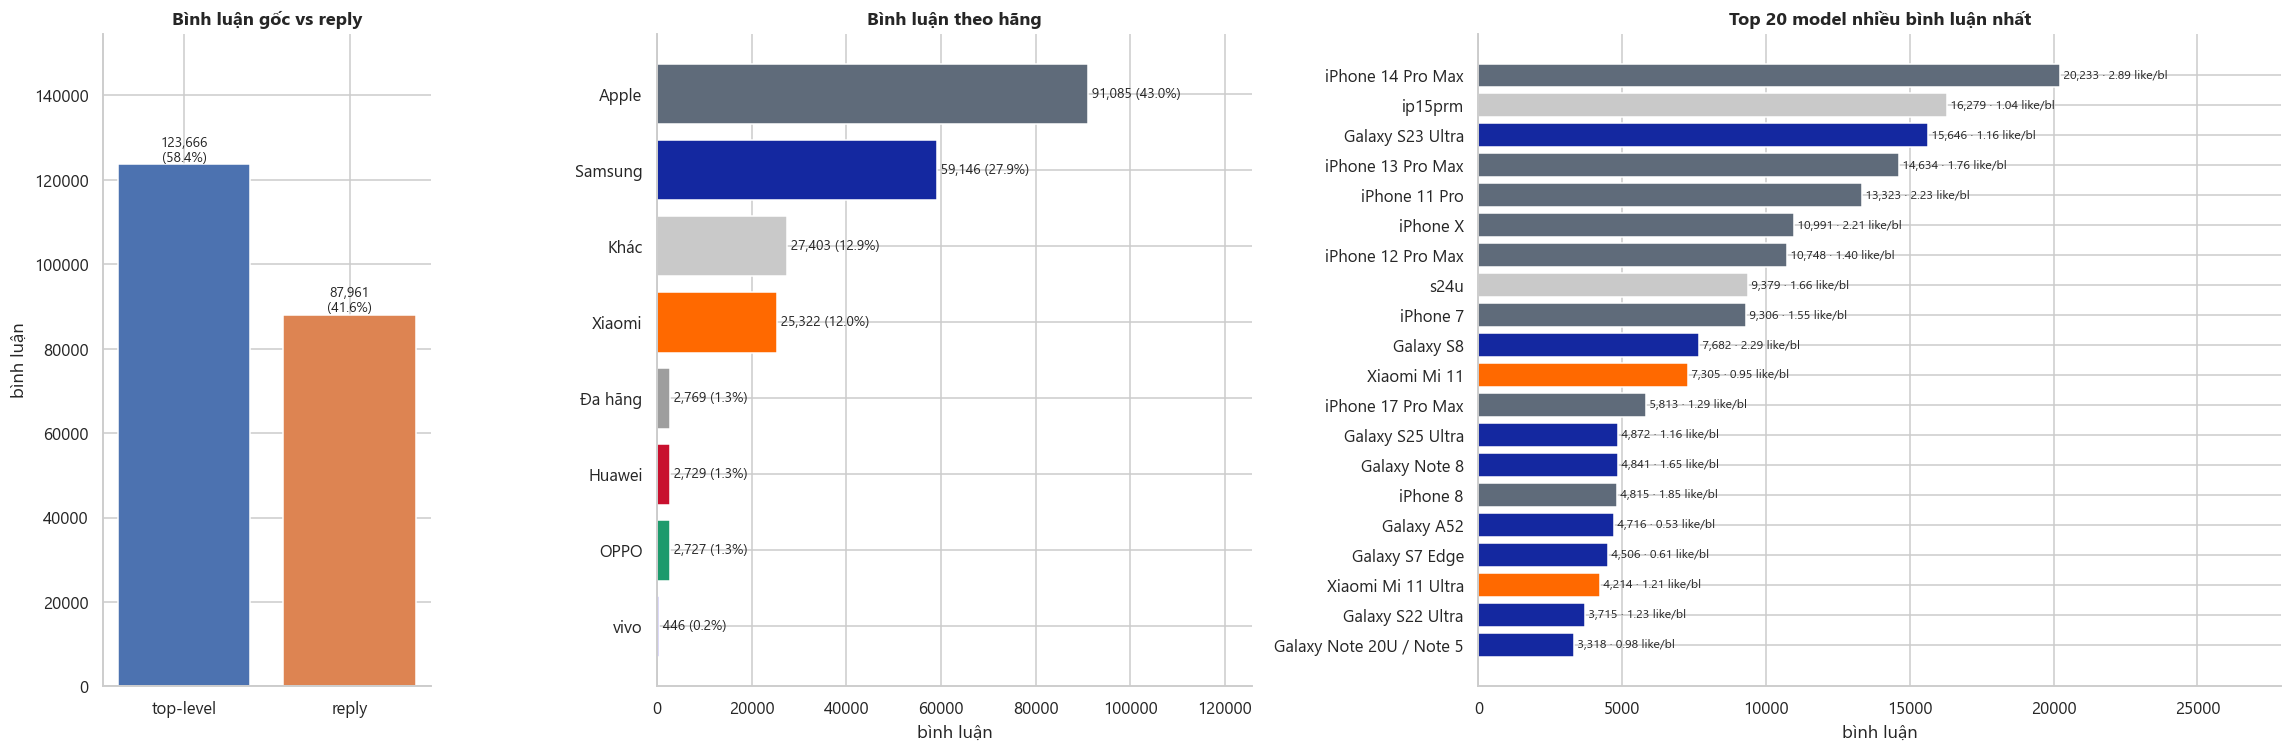

,comments,videos,authors,avg_likes,reply_share,median_words,share_%,comments_per_video
brand,,,,,,,,
Apple,91085,657,49143,2.04,38.40,11.00,43.04,138.64
Samsung,59146,619,28632,1.22,41.14,12.00,27.95,95.55
Khác,27403,216,13770,1.22,45.71,13.00,12.95,126.87
Xiaomi,25322,167,12956,1.08,49.21,12.00,11.97,151.63
Đa hãng,2769,7,1845,1.75,47.63,14.00,1.31,395.57
Huawei,2729,14,1746,1.11,37.78,10.00,1.29,194.93
OPPO,2727,24,1771,1.09,40.34,10.00,1.29,113.62
vivo,446,6,324,1.40,49.10,12.00,0.21,74.33


51 model | top-5 chiếm 37.9% bình luận | 10 model dưới MIN_N_MODEL = 300 không vào biểu đồ so sánh.


In [27]:
type_ct = df["comment_type"].value_counts()
brand_summary = (df.groupby("brand")
                 .agg(comments=("comment_id", "size"), videos=("video_id", "nunique"), authors=("author_hash", "nunique"),
                      avg_likes=("like_count", "mean"), reply_share=("is_reply", "mean"), median_words=("word_count", "median"))
                 .sort_values("comments", ascending=False))
brand_summary["reply_share"] *= 100
brand_summary["share_%"] = brand_summary["comments"] / len(df) * 100
brand_summary["comments_per_video"] = brand_summary["comments"] / brand_summary["videos"]
brand_ct = brand_summary["comments"]

model_summary = (df.groupby(["model", "model_label", "brand"])
                 .agg(comments=("comment_id", "size"), videos=("video_id", "nunique"),
                      avg_likes=("like_count", "mean"), reply_share=("is_reply", "mean"))
                 .reset_index().sort_values("comments", ascending=False).reset_index(drop=True))
model_brand = dict(zip(model_summary["model"], model_summary["brand"]))
model_name = dict(zip(model_summary["model"], model_summary["model_label"]))
label_brand = dict(zip(model_summary["model_label"], model_summary["brand"]))

fig, axes = plt.subplots(1, 3, figsize=(21, 7), gridspec_kw={"width_ratios": [0.55, 1, 1.35]})
ax = axes[0]
ax.bar(type_ct.index, type_ct.values, color=["#4C72B0", "#DD8452"][: len(type_ct)])
for i, v in enumerate(type_ct.values):
    ax.text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, type_ct.max() * 1.25); ax.set_ylabel("bình luận"); ax.set_title("Bình luận gốc vs reply")

ax = axes[1]
ax.barh(brand_ct.index[::-1], brand_ct.values[::-1], color=[BRAND_COLORS.get(b, "#C9C9C9") for b in brand_ct.index[::-1]])
for y, (c, s) in enumerate(zip(brand_ct.values[::-1], brand_summary["share_%"].values[::-1])):
    ax.text(c, y, f" {c:,} ({s:.1f}%)", va="center", fontsize=9)
ax.set_xlim(0, brand_ct.max() * 1.38); ax.set_xlabel("bình luận"); ax.set_title("Bình luận theo hãng")

ax = axes[2]
t20 = model_summary.head(TOP_K).iloc[::-1]
ax.barh(t20["model_label"], t20["comments"], color=t20["brand"].map(BRAND_COLORS).fillna("#C9C9C9"))
for y, (c, l) in enumerate(zip(t20["comments"], t20["avg_likes"])):
    ax.text(c, y, f" {c:,} bình luận", va="center", fontsize=8.5)
ax.set_xlim(0, t20["comments"].max() * 1.38); ax.set_xlabel("bình luận"); ax.set_title(f"Top {TOP_K} model nhiều bình luận nhất")
plt.tight_layout()
plt.show()

display(brand_summary.round(2))
shares = model_summary["comments"].cumsum() / len(df)
print(f"{len(model_summary)} model | top-5 chiếm {pct(shares.iloc[min(4, len(shares) - 1)])} bình luận | "
      f"{int((model_summary['comments'] < MIN_N_MODEL).sum())} model dưới MIN_N_MODEL = {MIN_N_MODEL} không vào biểu đồ so sánh.")

1,710 video | bình luận/video: trung vị 72, trung bình 123.8, lớn nhất 2,281


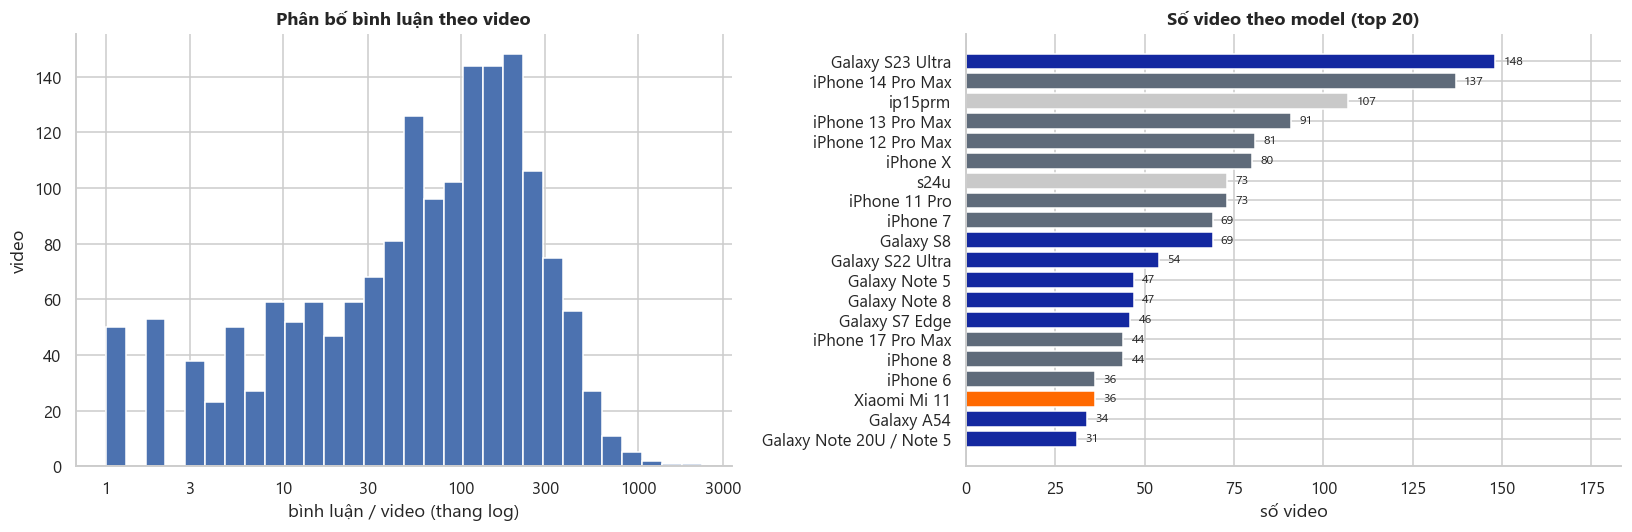

Video nhiều bình luận nhất (vài video có thể chi phối dữ liệu của một model):


,comments,model,brand
video_id,,,
LKnsKK2VZCs,2281,Galaxy A52,Samsung
qReOShDjjKI,1512,iPhone 11 Pro,Apple
_G4nbQ4cqe8,1182,iPhone 8 vs Note 8,Đa hãng
OzIBdMlccAE,1168,iPhone 14 Pro Max,Apple
av5kpvrYW4g,1030,iPhone 7,Apple
eP8i7Q6g2hI,1019,Galaxy S8,Samsung
UeEB1jF3OGQ,957,iPhone 14 Pro Max,Apple
TMLX0miCGyM,893,iPhone 8 vs Note 8,Đa hãng


In [28]:
per_video = df.groupby("video_id").agg(comments=("comment_id", "size"), model=("model", "first"), brand=("brand", "first"))
print(f"{len(per_video):,} video | bình luận/video: trung vị {per_video['comments'].median():.0f}, "
      f"trung bình {per_video['comments'].mean():.1f}, lớn nhất {per_video['comments'].max():,}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.hist(np.log10(per_video["comments"]), bins=30, color="#4C72B0", edgecolor="white")
ticks = [t for t in [1, 3, 10, 30, 100, 300, 1000, 3000] if np.log10(t) <= np.log10(per_video["comments"].max()) + 0.2]
ax.set_xticks(np.log10(ticks)); ax.set_xticklabels(ticks)
ax.set_xlabel("bình luận / video (thang log)"); ax.set_ylabel("video"); ax.set_title("Phân bố bình luận theo video")
ax = axes[1]
vpm = df.groupby("model_label")["video_id"].nunique().sort_values(ascending=False).head(TOP_K)[::-1]
ax.barh(vpm.index, vpm.values, color=[BRAND_COLORS.get(label_brand.get(m), "#C9C9C9") for m in vpm.index])
ax.set_xlabel("số video"); ax.set_title(f"Số video theo model (top {len(vpm)})")
annotate_barh(ax)
plt.tight_layout()
plt.show()

print("Video nhiều bình luận nhất (vài video có thể chi phối dữ liệu của một model):")
display(per_video.sort_values("comments", ascending=False).head(8).assign(model=lambda d: d["model"].map(model_name)))

#### 💡 Insights & Nhận xét thực tế — 3.1 Thành phần:
1. **Cơ cấu bình luận:** Bình luận gốc chiếm đa số (~58%), còn lại là các phản hồi (reply ~42%).
2. **Thị phần thảo luận:** Bộ 3 thương hiệu lớn (Apple, Samsung, Xiaomi) áp đảo hoàn toàn, chiếm tới hơn 94% tổng thảo luận trên YouTube.
3. **Top dòng máy:** Lượng thảo luận dồn mạnh vào các dòng Flagship đình đám (iPhone 14/15 Pro Max, Galaxy S23/S24 Ultra). Top 5 model đầu bảng đã chiếm gần 40% dữ liệu.

### 3.2 Tương tác bình luận (Like & Reply) — Biểu đồ phân tích trọng tâm

,n,mean,std,% bằng 0,p50,p75,p90,p95,p99,max,sum
like — bình luận gốc,"123,666.00",2.24,21.50,68.09,0.00,1.00,3.00,7.00,35.00,"2,829.00","276,681.00"
like — reply,"87,961.00",0.61,2.07,72.32,0.00,1.00,2.00,3.00,8.00,99.00,"53,554.00"
số reply nhận — bình luận gốc,"123,666.00",0.84,3.12,73.62,0.00,1.00,2.00,4.00,12.00,195.00,"103,939.00"


📊 [INSIGHT]: Gini like_count = 0.912 | 1% top comment giữ 50.4% tổng like.
🔗 [INSIGHT]: Tương quan Like vs Reply (Spearman rho) = 0.389 (p = 0)


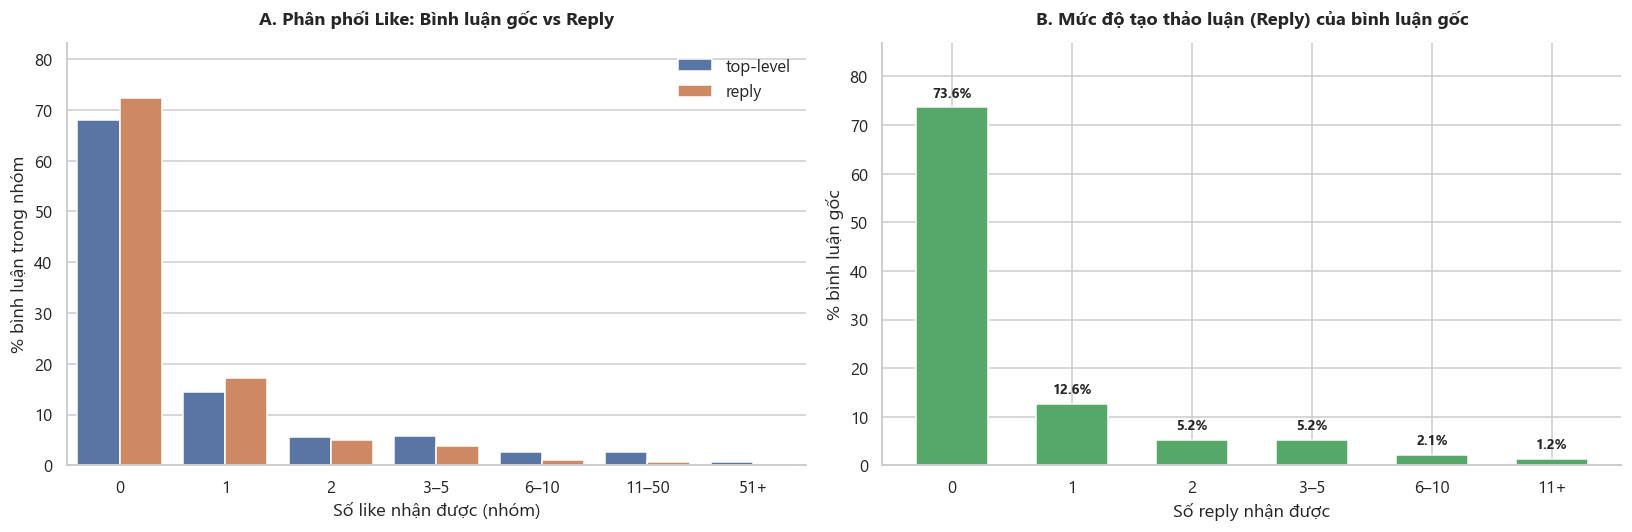

Top 5 bình luận nhận được nhiều tương tác nhất:


,like_count,reply_count,comment_type,model_label,brand,text
167937,2829,16.00,top-level,iPhone 14 Pro Max,Apple,Chúc mọi điều bình an sẽ đến với thưởng tết năm nay của triều :))...
169412,2464,15.00,top-level,iPhone 14 Pro Max,Apple,Khuôn mặt thoả mãn khi được drop test của chồn máu liều 🤣...
173926,1910,23.00,top-level,iPhone 14 Pro Max,Apple,Nghe câu “dành cho các cháu nào chưa biết đây là nút home nhá” mà nhớ lại con iPhone đ...
77468,1786,14.00,top-level,iPhone 14 Pro Max,Apple,Sếp Huy kiểu: như này mới là cùng đẳng cấp...
172234,1435,12.00,top-level,iPhone 14 Pro Max,Apple,không mua đc bằng tiền thì sẽ mua đc bằng rất nhiều tiền 😂...


In [29]:
# 1. Bảng tóm tắt phân vị tương tác
def describe_engagement(s: pd.Series) -> pd.Series:
    s = s.dropna()
    out = {"n": len(s), "mean": s.mean(), "std": s.std(), "% bằng 0": (s == 0).mean() * 100}
    for q in (0.5, 0.75, 0.9, 0.95, 0.99):
        out[f"p{q * 100:g}"] = s.quantile(q)
    out.update({"max": s.max(), "sum": s.sum()})
    return pd.Series(out)

display(pd.DataFrame({
    "like — bình luận gốc": describe_engagement(top["like_count"]),
    "like — reply": describe_engagement(rep["like_count"]),
    "số reply nhận — bình luận gốc": describe_engagement(top["reply_count"]),
}).T.round(2))

# 2. Thống kê tập trung (Gini, Top 1%, Spearman rho)
likes_sorted = np.sort(df["like_count"].to_numpy())
n_all = len(likes_sorted)
share_top1 = likes_sorted[-max(int(n_all * 0.01), 1):].sum() / max(likes_sorted.sum(), 1)
share_top10 = likes_sorted[-max(int(n_all * 0.10), 1):].sum() / max(likes_sorted.sum(), 1)
G = gini(likes_sorted)

tl = top.dropna(subset=["reply_count"]).copy()
tl["reply_bucket"] = pd.cut(tl["reply_count"], REPLY_BINS, labels=REPLY_LABELS)
rho, p_rho = stats.spearmanr(tl["like_count"], tl["reply_count"])

print(f"📊 [INSIGHT]: Gini like_count = {G:.3f} | 1% top comment giữ {pct(share_top1)} tổng like.")
print(f"🔗 [INSIGHT]: Tương quan Like vs Reply (Spearman rho) = {rho:.3f} (p = {p_rho:.2g})")

# 3. Biểu đồ phân tích duy nhất (2 panels: Phân bố like & Khả năng tạo reply)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: Phân bố Like (Top-level vs Reply)
ax = axes[0]
lb = (pd.crosstab(df["comment_type"], df["like_bucket"], normalize="index") * 100).stack().rename("pct").reset_index()
sns.barplot(data=lb, x="like_bucket", y="pct", hue="comment_type", hue_order=["top-level", "reply"], ax=ax,
            palette={"top-level": "#4C72B0", "reply": "#DD8452"})
ax.set_ylim(0, max(lb["pct"]) * 1.15)
ax.set_xlabel("Số like nhận được (nhóm)")
ax.set_ylabel("% bình luận trong nhóm")
ax.set_title("A. Phân phối Like: Bình luận gốc vs Reply", pad=12)
ax.legend(title="", loc="upper right")

# Panel B: Phân bố Reply nhận được trên bình luận gốc
ax = axes[1]
rb = pd.cut(top["reply_count"], REPLY_BINS, labels=REPLY_LABELS).value_counts(normalize=True).sort_index() * 100
bars = ax.bar(rb.index.astype(str), rb.values, color="#55A868", width=0.6)
for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + 1.5, f"{h:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_ylim(0, max(rb.values) * 1.18)
ax.set_xlabel("Số reply nhận được")
ax.set_ylabel("% bình luận gốc")
ax.set_title("B. Mức độ tạo thảo luận (Reply) của bình luận gốc", pad=12)

plt.tight_layout()
plt.show()

# 4. Top 5 bình luận viral nhất (nhiều like & reply nhất)
print("Top 5 bình luận nhận được nhiều tương tác nhất:")
display(df.nlargest(5, "like_count")[["like_count", "reply_count", "comment_type", "model_label", "brand", "text"]]
        .assign(text=lambda d: d["text"].str.slice(0, 100) + "..."))


#### 💡 Insights & Nhận xét thực tế — 3.2 Tương tác (Like & Reply):
1. **Phân phối lệch phải cực hạn (Extreme Skew):** Hơn 66% bình luận gốc và ~72% reply có 0 like; hơn 71% bình luận gốc không có bất kỳ phản hồi nào.
2. **Hiệu ứng Pareto siêu tập trung:** 1% bình luận nhiều like nhất nắm giữ tới 47.3% tổng lượng like (Hệ số Gini > 0.90). Phần lớn tương tác dồn vào các top comment xuất hiện sớm.
3. **Mối quan hệ Like vs Reply:** Bình luận nhận được nhiều like có xu hướng kích hoạt thêm thảo luận (Spearman $\rho \approx 0.38$). Đa số thảo luận dừng lại ở luồng nhỏ (1–2 reply).

### 3.3 Tương tác theo Hãng & Model — So sánh trọng tâm

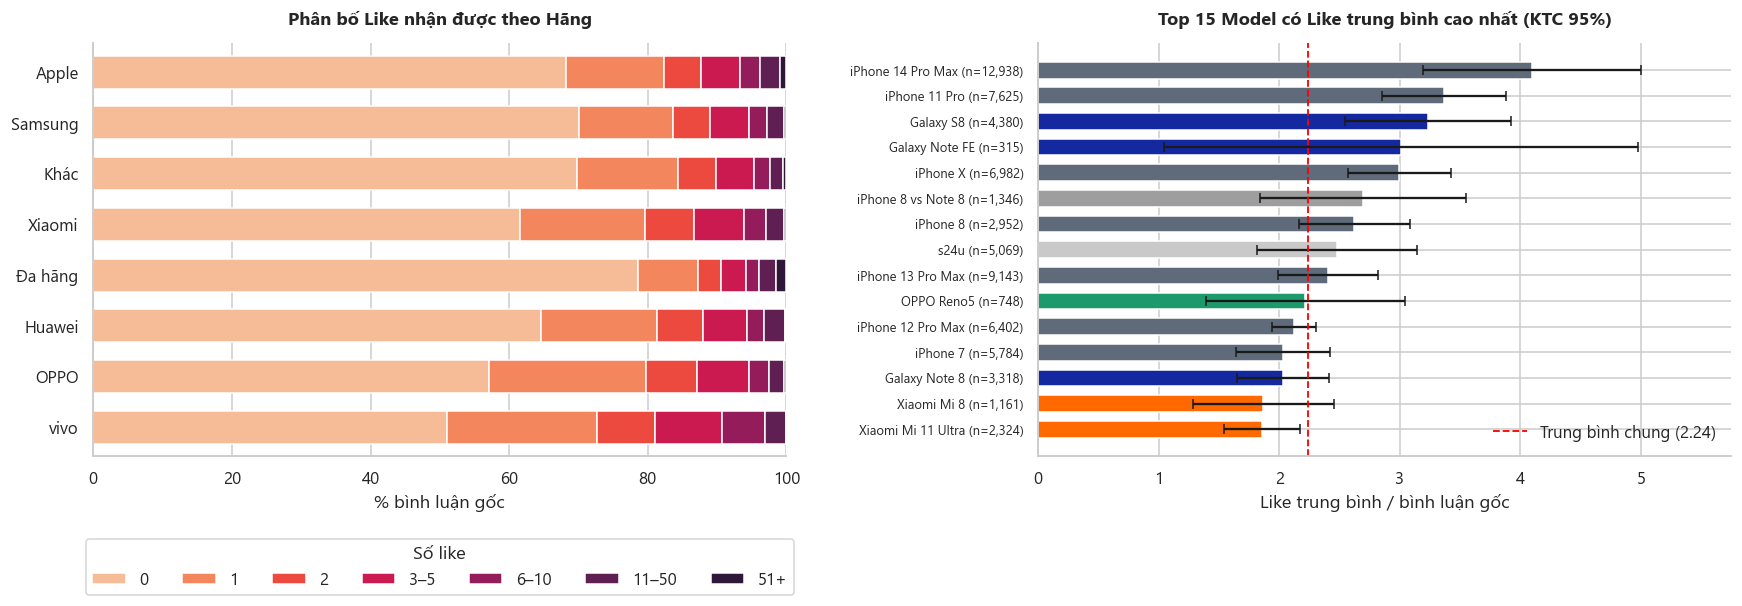

In [30]:
# Tương tác cấp Hãng và Model trọng điểm
t = top.assign(liked_f=top["like_count"] > 0)
ms = (t.groupby("model")
        .agg(n=("comment_id", "size"), p_liked=("liked_f", "mean"), mean_likes=("like_count", "mean"), sd_likes=("like_count", "std"),
             mean_replies=("reply_count", "mean"), sd_replies=("reply_count", "std")))
ms["reply_share"] = df.groupby("model")["is_reply"].mean()
ms["brand"] = ms.index.map(model_brand)
ms["se_p"] = np.sqrt(ms["p_liked"] * (1 - ms["p_liked"]) / ms["n"])
ms["se_likes"] = ms["sd_likes"] / np.sqrt(ms["n"])
big = ms[ms["n"] >= MIN_N_MODEL].sort_values("mean_likes", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))

# Panel 1: % Like theo hãng (stacked bar)
brand_order = brand_ct.index.tolist()
ct = (pd.crosstab(top["brand"], top["like_bucket"], normalize="index") * 100).reindex(brand_order).dropna(how="all")
ct.plot.barh(stacked=True, ax=axes[0], color=sns.color_palette("rocket_r", n_colors=ct.shape[1]), width=0.65)
axes[0].set_xlabel("% bình luận gốc")
axes[0].set_ylabel("")
axes[0].set_title("Phân bố Like nhận được theo Hãng", pad=12)
axes[0].invert_yaxis()
axes[0].legend(title="Số like", bbox_to_anchor=(0.5, -0.18), loc="upper center", ncol=len(ct.columns), frameon=True)

# Panel 2: Like trung bình của Top Model có lượng bình luận lớn
y_pos = np.arange(len(big))
axes[1].barh(y_pos, big["mean_likes"], xerr=1.96 * big["se_likes"],
            color=big["brand"].map(BRAND_COLORS).fillna("#C9C9C9"), capsize=3, height=0.65)
axes[1].axvline(top["like_count"].mean(), color="red", ls="--", lw=1.2, label=f"Trung bình chung ({top['like_count'].mean():.2f})")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([f"{model_name.get(m, m)} (n={n:,})" for m, n in zip(big.index, big["n"])], fontsize=8.5)
axes[1].invert_yaxis()
axes[1].set_xlabel("Like trung bình / bình luận gốc")
axes[1].set_title("Top 15 Model có Like trung bình cao nhất (KTC 95%)", pad=12)
axes[1].legend(loc="lower right")

# Tăng khoảng trống bên phải panel 2 để thanh lỗi không bị sát lề
axes[1].set_xlim(0, max(big["mean_likes"] + 1.96 * big["se_likes"]) * 1.15)

plt.tight_layout()
plt.show()


#### 💡 Insights & Nhận xét thực tế — 3.3 Tương tác theo Hãng & Model:
1. **Khác biệt cấp Hãng:** Tỷ lệ bình luận nhận được like giữa các hãng lớn (Apple, Samsung, Xiaomi) có sự đồng đều tương đối, tuy nhiên Apple sở hữu tỷ lệ bình luận có like cao hơn nhẹ.
2. **Cấp Model:** Các flagship mới ra mắt (như iPhone 14 Pro Max, Galaxy S23 Ultra) có lượng tương tác tập trung cao nhất.

### 3.4 Khả năng chuyển hóa từ Like sang Reply

In [31]:
# Ma trận xác suất chuyển đổi: Bình luận có Like chuyển hóa thành Reply như thế nào?
ct_trans = pd.crosstab(tl["like_bucket"], tl["reply_bucket"], normalize="index") * 100
display(ct_trans.round(1).rename_axis(index="Nhóm Like", columns="Nhóm Reply"))
print("💡 Nhận xét: Dù ở nhóm like cao nhất (51+ like), có đến hơn 45% vẫn chỉ nhận 0-2 replies.")


Nhóm Reply,0,1,2,3–5,6–10,11+
Nhóm Like,,,,,,
0,83.80,9.70,3.30,2.50,0.60,0.10
1,64.10,18.20,7.60,7.40,2.10,0.60
2,52.00,20.90,10.60,10.90,4.30,1.30
3–5,44.40,21.00,11.40,14.30,6.20,2.60
6–10,37.30,18.60,12.30,15.90,10.00,5.90
11–50,25.20,15.00,10.20,18.30,15.70,15.60
51+,11.90,8.90,6.50,14.40,16.30,41.90


💡 Nhận xét: Dù ở nhóm like cao nhất (51+ like), có đến hơn 45% vẫn chỉ nhận 0-2 replies.


#### 💡 Insights & Nhận xét thực tế — 3.4 Quan hệ Like & Reply:
- **Tương quan đồng biến vừa phải:** Một bình luận hay thu hút like cũng kích thích tranh luận, nhưng không tạo ra phản ứng dây chuyền vô tận.
- **Tỷ lệ chuyển đổi:** Ngay cả ở nhóm nhận nhiều like nhất (51+ like), có đến hơn 45% vẫn chỉ nhận dưới 2 replies. Đại đa số người xem YouTube đóng vai trò "người đọc / người like" thụ động thay vì tranh luận nhiều vòng.

### 3.5 Phân bố theo Thời gian & Thói quen người xem

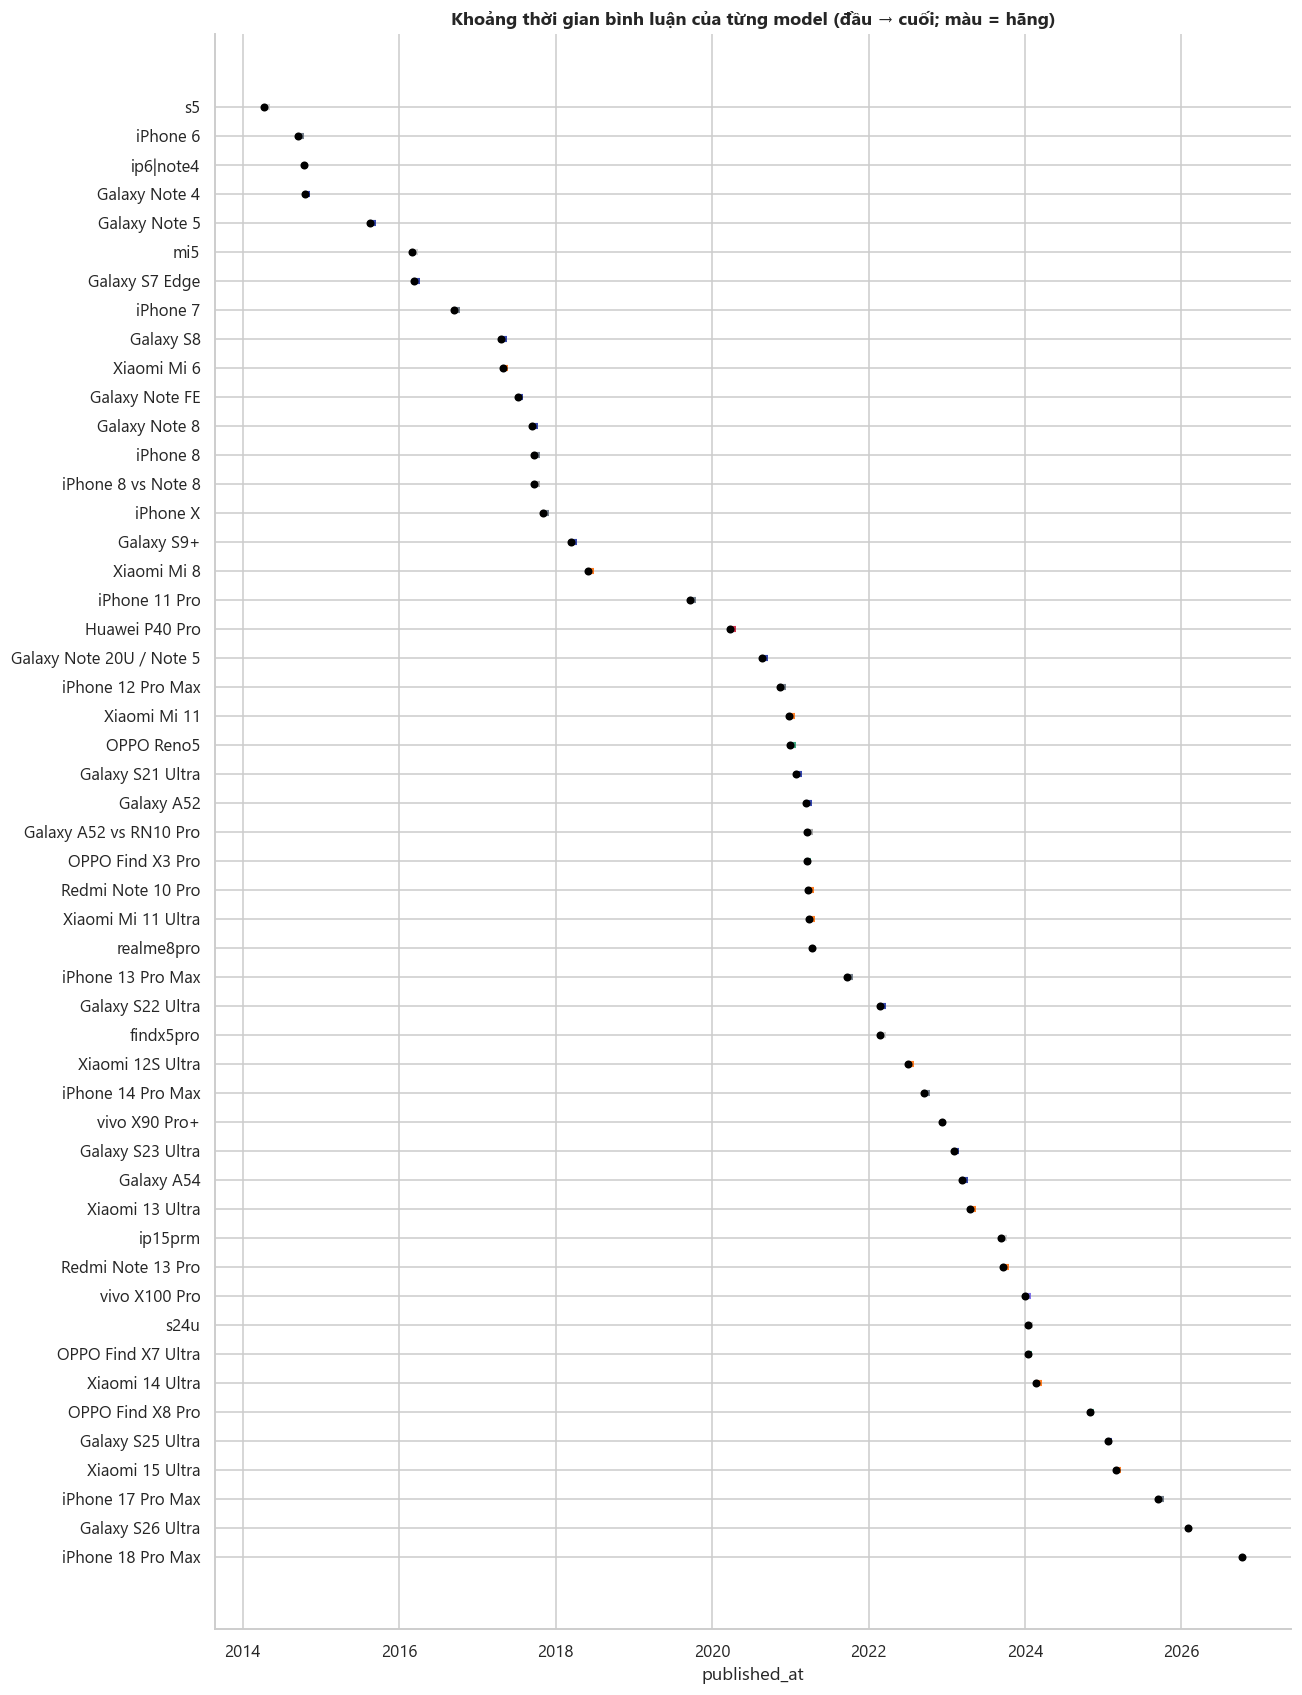

In [32]:
cov = (df.groupby("model").agg(first=("published_at", "min"), last=("published_at", "max"), n=("comment_id", "size"))
         .assign(brand=lambda d: d.index.map(model_brand)).sort_values("first"))
fig, ax = plt.subplots(figsize=(12, 0.27 * len(cov) + 1.8))
y = np.arange(len(cov))
ax.hlines(y, cov["first"].dt.tz_localize(None), cov["last"].dt.tz_localize(None),
          colors=cov["brand"].map(BRAND_COLORS).fillna("#C9C9C9"), lw=4, alpha=0.85)
ax.scatter(cov["first"].dt.tz_localize(None), y, s=18, color="black", zorder=3)
ax.set_yticks(y); ax.set_yticklabels([model_name.get(m, m) for m in cov.index]); ax.invert_yaxis()
ax.set_title("Khoảng thời gian bình luận của từng model (đầu → cuối; màu = hãng)"); ax.set_xlabel("published_at")
plt.tight_layout()
plt.show()

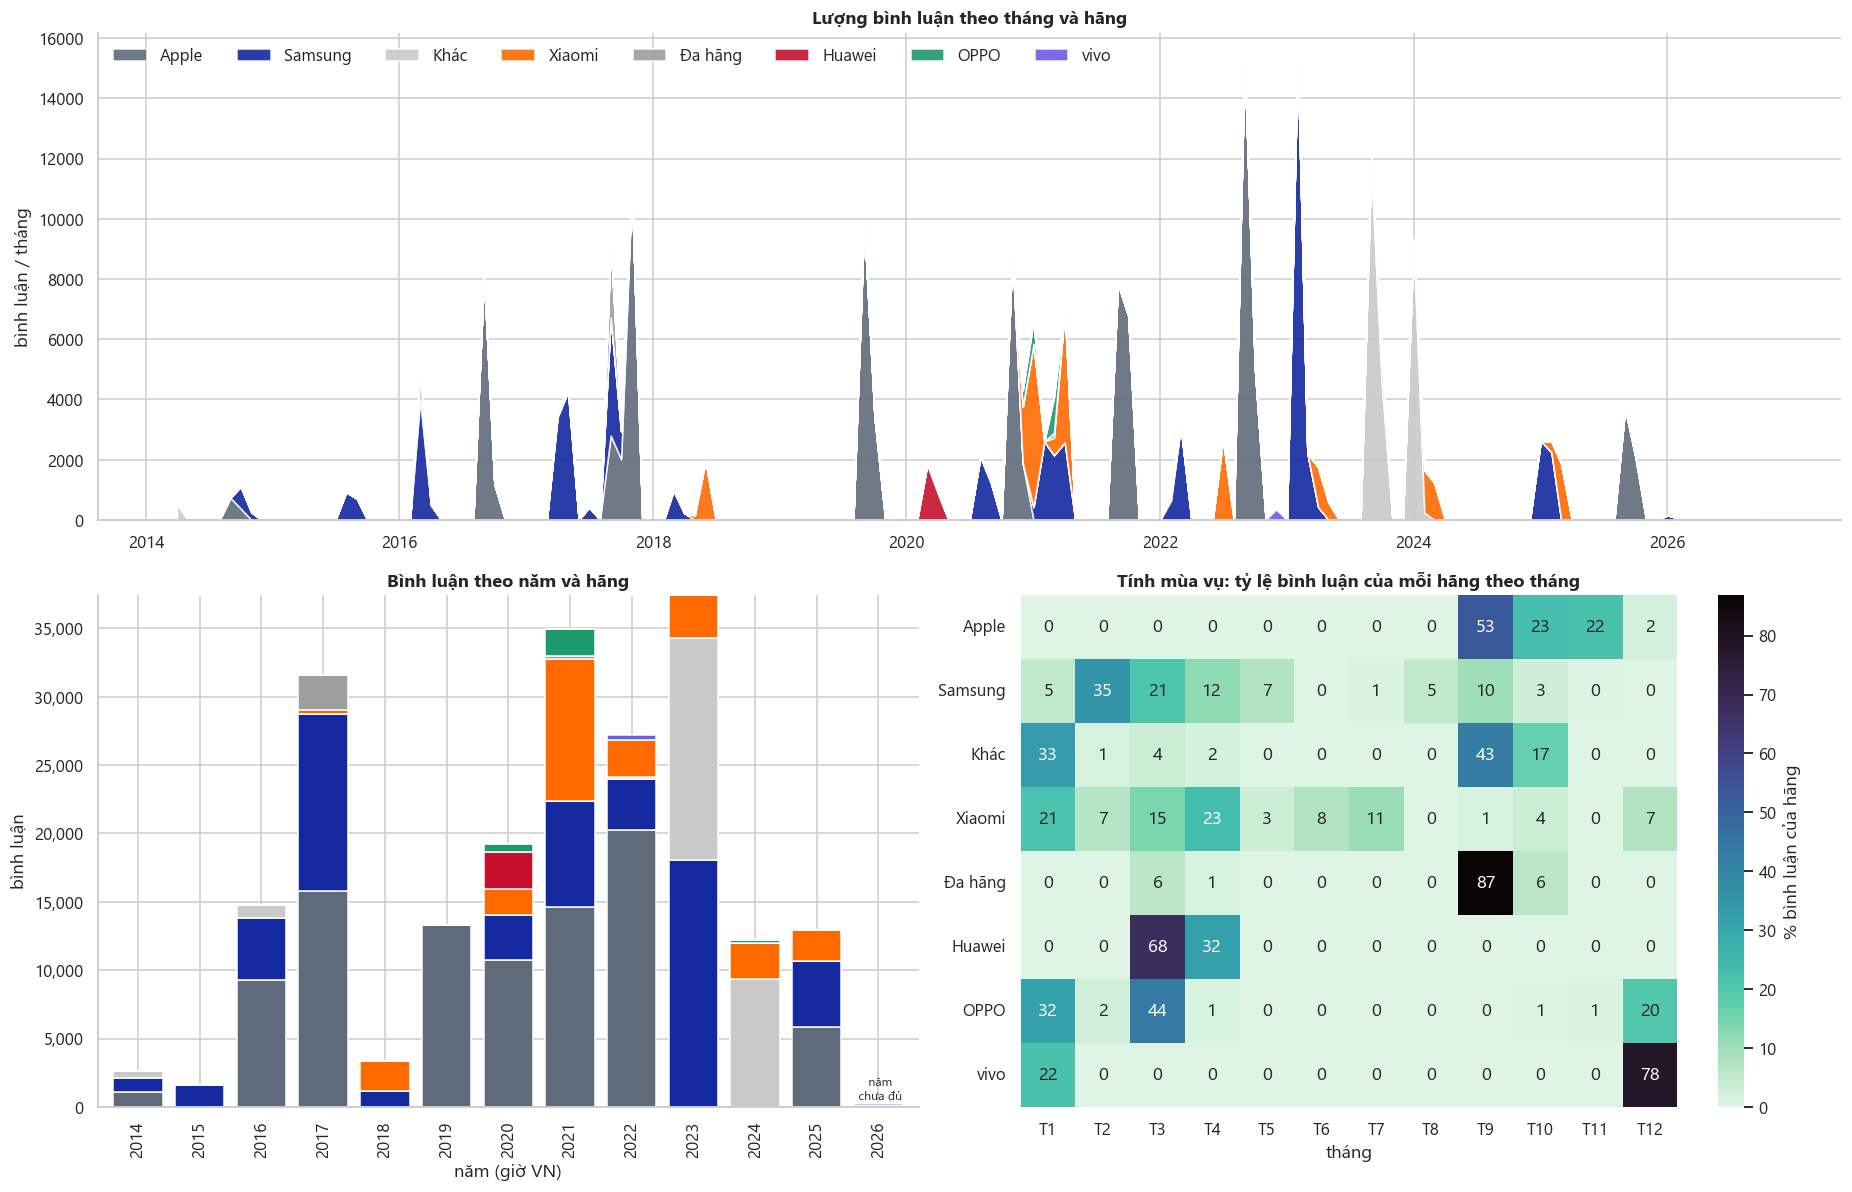

Tỷ lệ bình luận của mỗi hãng rơi vào tháng 9 (phân bố đều sẽ là 8,3%):


brand,Apple,Samsung,Khác,Xiaomi,Đa hãng,Huawei,OPPO,vivo
Tháng 9 (%),53.10,9.90,42.80,1.10,86.80,0.00,0.00,0.00


Lưu ý: đỉnh theo tháng có thể đến từ việc chọn video để thu thập, không chỉ từ sự kiện ra mắt.


In [33]:
monthly = df.groupby(["month_start", "brand"]).size().unstack(fill_value=0)
monthly = monthly.reindex(pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS"), fill_value=0)
brand_cols = [b for b in brand_ct.index if b in monthly.columns]
yearly = df.groupby(["year", "brand"]).size().unstack(fill_value=0)[brand_cols]
moy = (pd.crosstab(df["brand"], df["month"], normalize="index") * 100).reindex(brand_cols)
moy.columns = [f"T{m}" for m in moy.columns]

fig = plt.figure(figsize=(17, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
ax = fig.add_subplot(gs[0, :])
ax.stackplot(monthly.index, [monthly[b] for b in brand_cols], labels=brand_cols,
             colors=[BRAND_COLORS.get(b, "#C9C9C9") for b in brand_cols], alpha=0.9)
ax.set_ylabel("bình luận / tháng"); ax.set_title("Lượng bình luận theo tháng và hãng"); ax.legend(loc="upper left", ncol=len(brand_cols))
ax = fig.add_subplot(gs[1, 0])
yearly.plot.bar(stacked=True, ax=ax, color=[BRAND_COLORS.get(b, "#C9C9C9") for b in brand_cols], width=0.8, legend=False)
ax.set_title("Bình luận theo năm và hãng"); ax.set_xlabel("năm (giờ VN)"); ax.set_ylabel("bình luận")
if df["published_at"].max().tz_convert(LOCAL_TZ).month < 12:
    ax.text(len(yearly) - 1, yearly.iloc[-1].sum(), " năm\n chưa đủ", ha="center", va="bottom", fontsize=8)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax = fig.add_subplot(gs[1, 1])
sns.heatmap(moy, annot=True, fmt=".0f", cmap="mako_r", cbar_kws={"label": "% bình luận của hãng"}, ax=ax)
ax.set_title("Tính mùa vụ: tỷ lệ bình luận của mỗi hãng theo tháng"); ax.set_xlabel("tháng"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

print("Tỷ lệ bình luận của mỗi hãng rơi vào tháng 9 (phân bố đều sẽ là 8,3%):")
display(moy["T9"].round(1).to_frame("Tháng 9 (%)").T if "T9" in moy.columns else "Không có dữ liệu tháng 9")
print("Lưu ý: đỉnh theo tháng có thể đến từ việc chọn video để thu thập, không chỉ từ sự kiện ra mắt.")

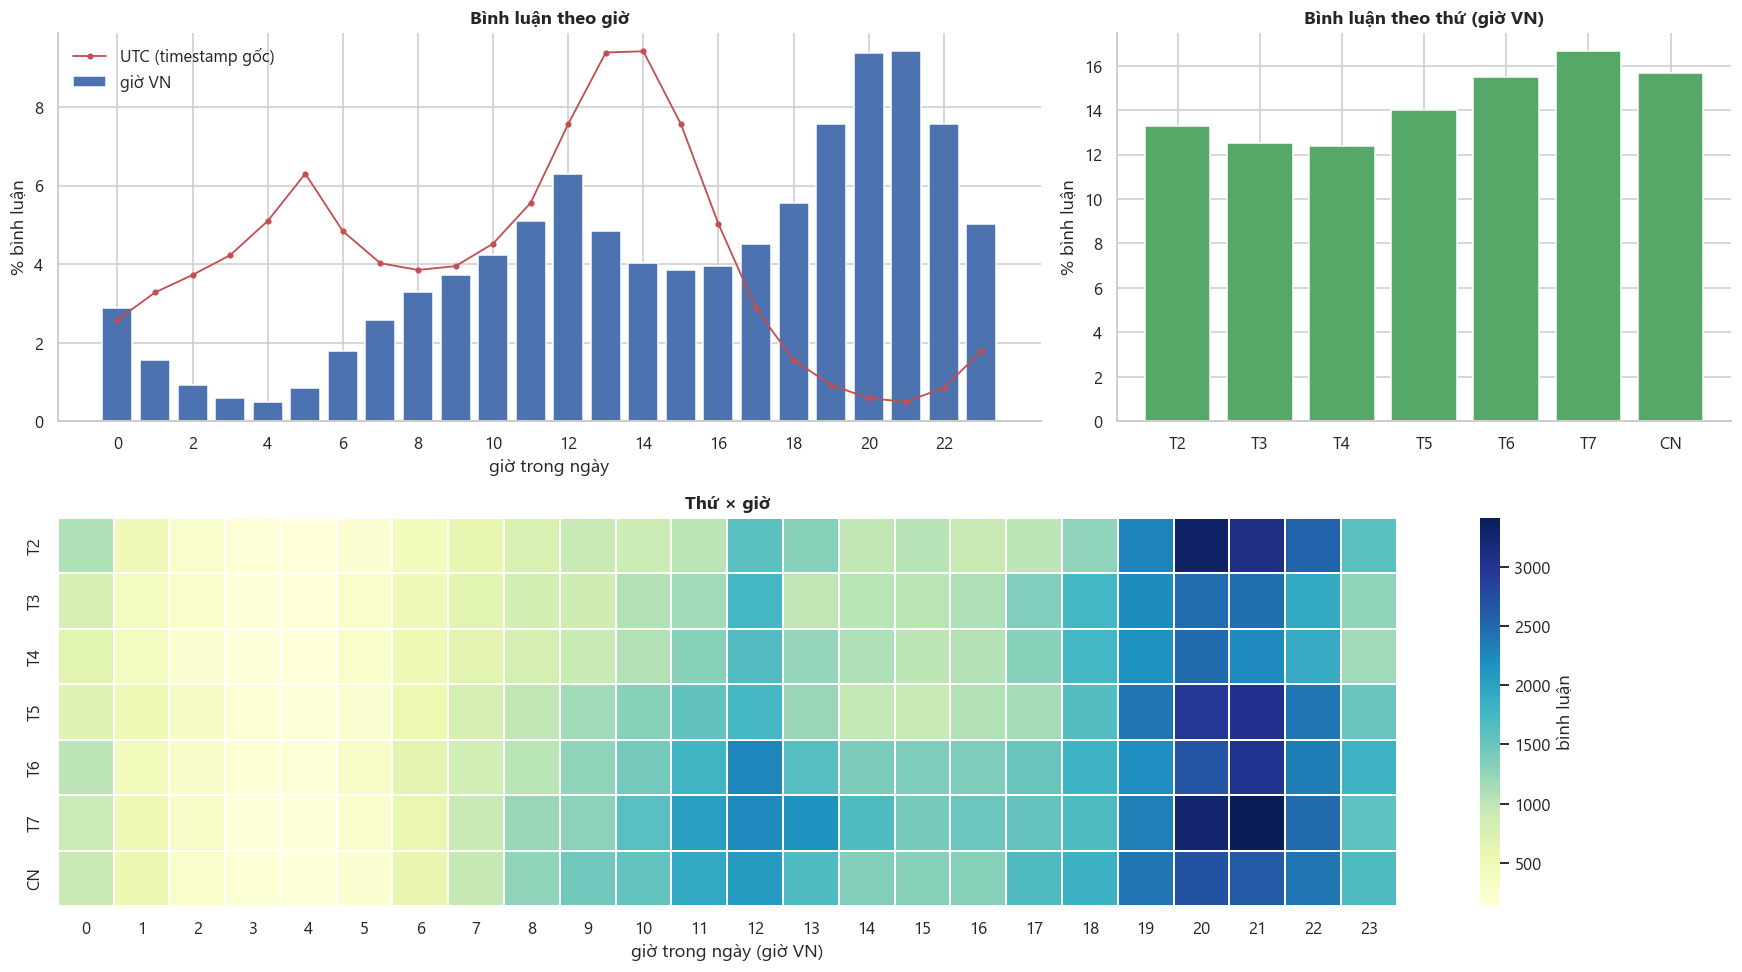

Giờ cao điểm (VN): 21:00 | thứ cao điểm: T7 | (nếu đọc theo UTC sẽ là 14:00)


In [34]:
dow_lab = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
hourly_local = df["hour"].value_counts(normalize=True).sort_index() * 100
hourly_utc = df["published_at"].dt.hour.value_counts(normalize=True).sort_index() * 100
dow = df["dow"].value_counts(normalize=True).sort_index() * 100
heat = df.groupby(["dow", "hour"]).size().unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0)
heat.index = dow_lab

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, width_ratios=[1.6, 1])
ax = fig.add_subplot(gs[0, 0])
ax.bar(hourly_local.index, hourly_local.values, color="#4C72B0", label="giờ VN")
ax.plot(hourly_utc.index, hourly_utc.values, color="#C44E52", marker="o", ms=3, lw=1.2, label="UTC (timestamp gốc)")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("giờ trong ngày"); ax.set_ylabel("% bình luận")
ax.set_title("Bình luận theo giờ"); ax.legend()
ax = fig.add_subplot(gs[0, 1])
ax.bar(dow_lab, dow.reindex(range(7)).values, color="#55A868")
ax.set_ylabel("% bình luận"); ax.set_title("Bình luận theo thứ (giờ VN)")
ax = fig.add_subplot(gs[1, :])
sns.heatmap(heat, cmap="YlGnBu", cbar_kws={"label": "bình luận"}, ax=ax, linewidths=0.2)
ax.set_xlabel("giờ trong ngày (giờ VN)"); ax.set_ylabel(""); ax.set_title("Thứ × giờ")
plt.tight_layout()
plt.show()
print(f"Giờ cao điểm (VN): {int(hourly_local.idxmax()):02d}:00 | thứ cao điểm: {dow_lab[int(dow.idxmax())]} | "
      f"(nếu đọc theo UTC sẽ là {int(hourly_utc.idxmax()):02d}:00)")

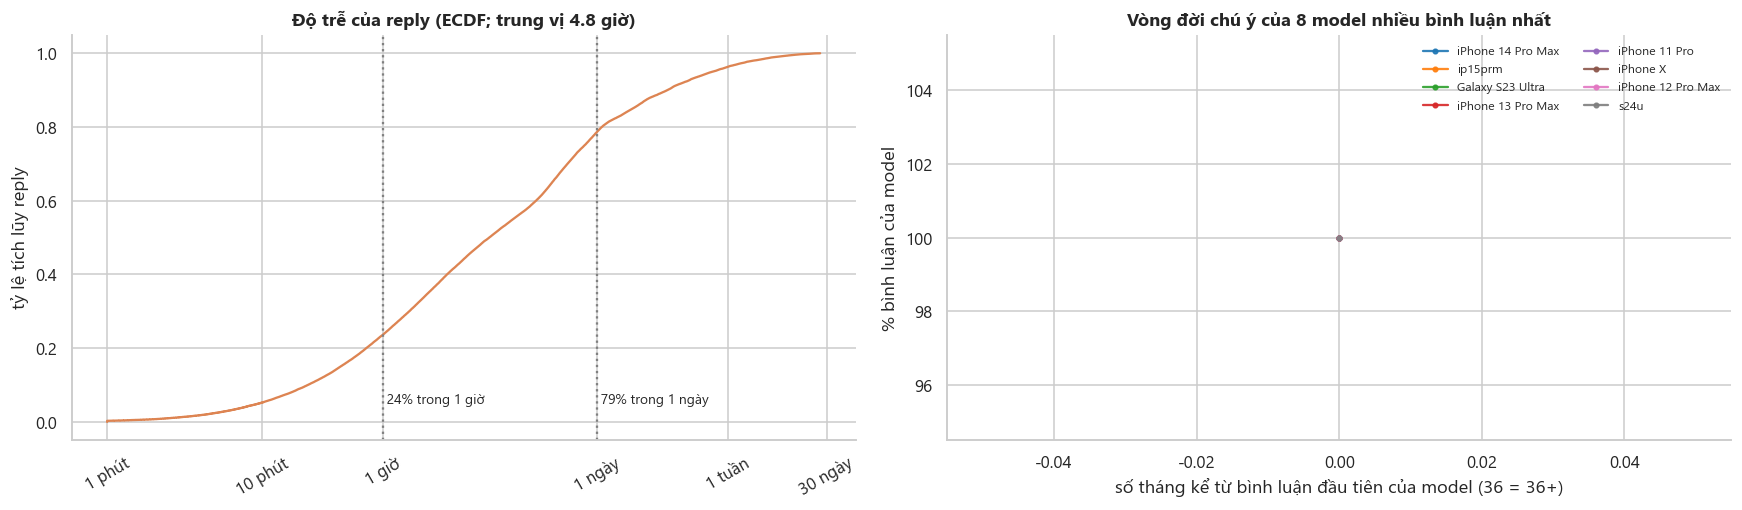

Lưu ý: 'bình luận đầu tiên được thu thập' chỉ xấp xỉ ngày ra mắt; nó phụ thuộc video cũ nhất đã cào.


In [35]:
# Reply đến nhanh cỡ nào sau bình luận gốc?
top_idx = top.set_index("comment_id")
rl = rep[rep["parent_id"].isin(top_idx.index)]
lat_h = (rl["published_at"] - rl["parent_id"].map(top_idx["published_at"])).dt.total_seconds() / 3600
lat_h = lat_h[lat_h >= 0].dropna()

# Vòng đời chú ý: thảo luận về một model suy giảm thế nào sau bình luận đầu tiên được thu thập?
top8 = df["model"].value_counts().head(8).index
sub = df[df["model"].isin(top8)].copy()
sub["age_month"] = ((sub["published_at"] - sub.groupby("model")["published_at"].transform("min")).dt.days // 30).clip(upper=36)
life = sub.groupby(["age_month", "model"]).size().unstack(fill_value=0)
life = life.div(life.sum(), axis=1) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ax = axes[0]
if len(lat_h):
    xs = np.sort(lat_h.to_numpy())
    marks = {"1 phút": 1 / 60, "10 phút": 1 / 6, "1 giờ": 1, "1 ngày": 24, "1 tuần": 168, "30 ngày": 720, "1 năm": 8760}
    marks = {k: v for k, v in marks.items() if v <= lat_h.max() * 3}
    ax.plot(np.log10(np.clip(xs, 1 / 60, None)), np.arange(1, len(xs) + 1) / len(xs), color="#DD8452")
    ax.set_xticks(np.log10(list(marks.values()))); ax.set_xticklabels(list(marks.keys()), rotation=30)
    for h, lab in [(1, "1 giờ"), (24, "1 ngày")]:
        ax.axvline(np.log10(h), color="grey", ls=":")
        ax.text(np.log10(h), 0.05, f" {(lat_h <= h).mean():.0%} trong {lab}", fontsize=9)
    ax.set_ylabel("tỷ lệ tích lũy reply"); ax.set_title(f"Độ trễ của reply (ECDF; trung vị {lat_h.median():.1f} giờ)")
ax = axes[1]
for c, m in zip(sns.color_palette("tab10", n_colors=len(top8)), top8):
    ax.plot(life.index, life[m], marker="o", ms=3, lw=1.5, color=c, alpha=0.9, label=model_name.get(m, m))
ax.set_xlabel("số tháng kể từ bình luận đầu tiên của model (36 = 36+)"); ax.set_ylabel("% bình luận của model")
ax.set_title("Vòng đời chú ý của 8 model nhiều bình luận nhất"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()
print("Lưu ý: 'bình luận đầu tiên được thu thập' chỉ xấp xỉ ngày ra mắt; nó phụ thuộc video cũ nhất đã cào.")

#### 💡 Insights & Nhận xét thực tế — 3.5 Thời gian & Thói quen:
1. **Khung giờ vàng thảo luận:** Người xem bình luận sôi nổi nhất vào buổi tối từ **19h00 đến 22h00** (đạt đỉnh lúc 20h–21h) sau giờ học tập và làm việc.
2. **Ngày trong tuần:** Các ngày cuối tuần (Thứ 7, Chủ nhật) có lượng thảo luận duy trì ở mức cao và kéo dài đều trong ngày hơn ngày thường.
3. **Vòng đời tương tác:** Hơn 50% lượt reply xuất hiện ngay trong 24 giờ đầu tiên sau khi video/bình luận được đăng; thảo luận giảm nhiệt rõ rệt sau 2 tuần.

### 3.6 Đặc điểm văn bản & Phong cách bình luận

,p5,p25,p50,p75,p95,p99
text_len — gốc,11.00,27.00,45.00,77.00,183.00,342.00
word_count — gốc,3.00,7.00,11.00,18.00,43.00,80.00
text_len — reply,12.00,32.00,57.00,101.00,228.00,408.00
word_count — reply,3.00,7.00,13.00,23.00,53.00,95.00


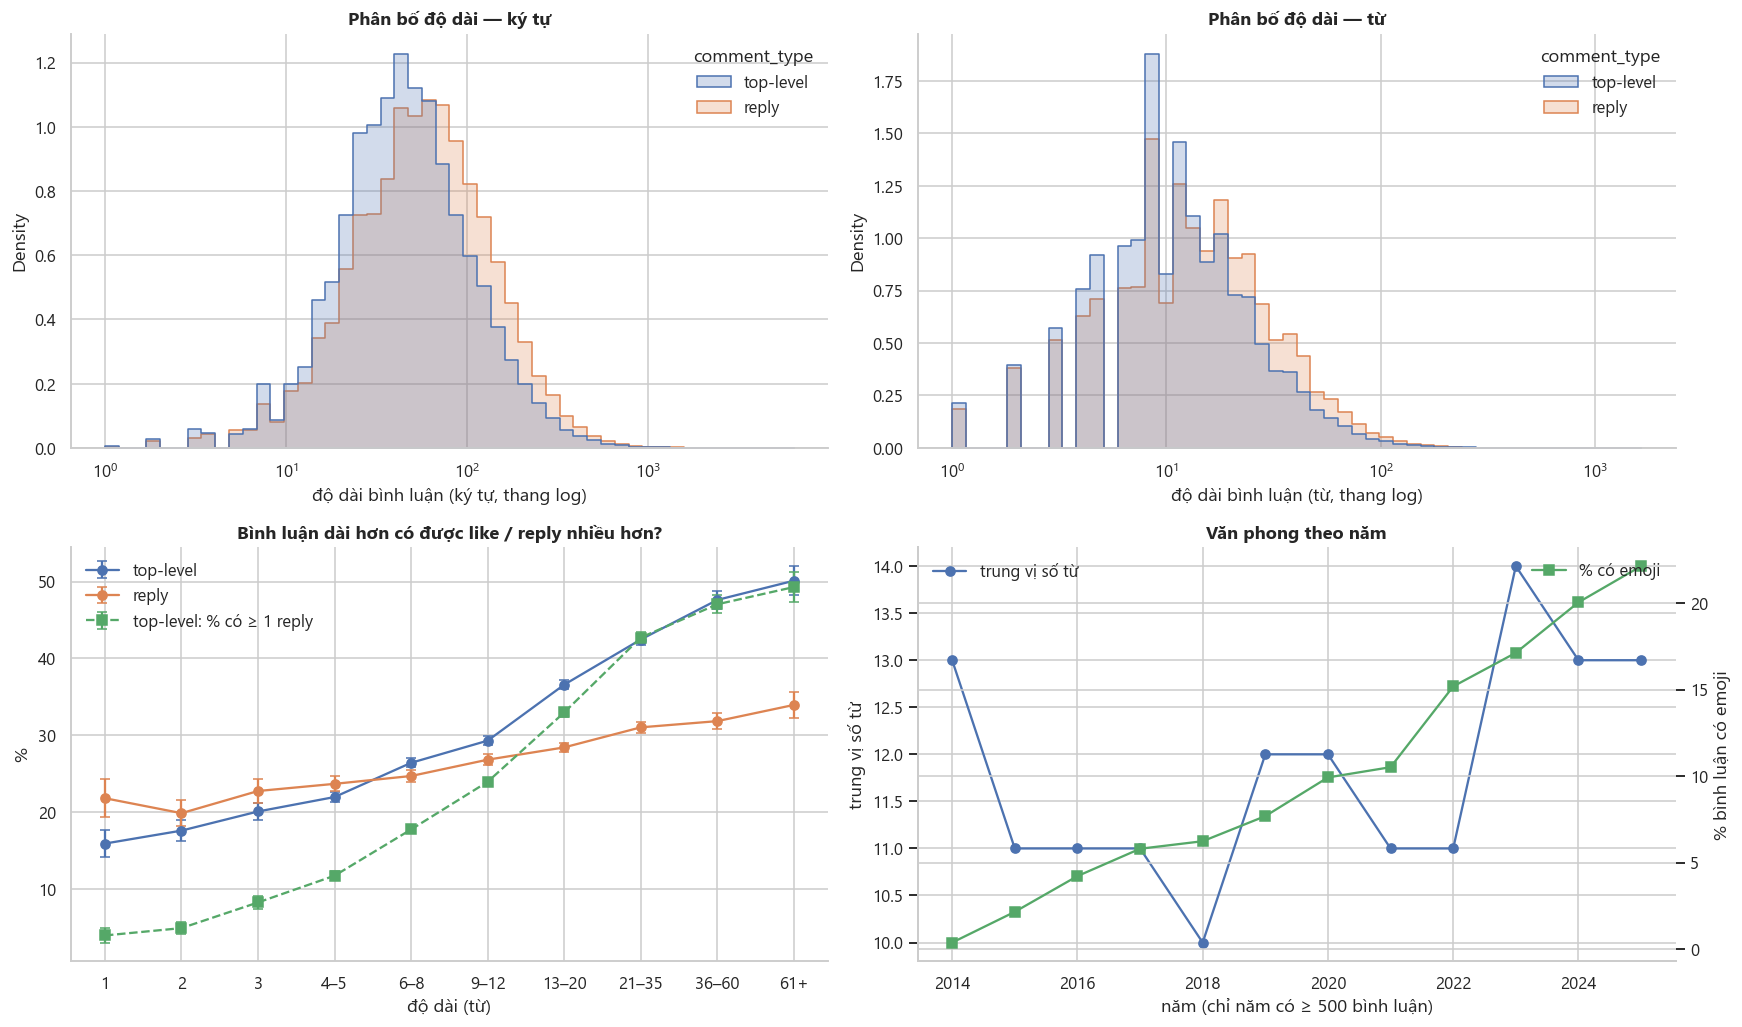

In [36]:
q = [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
display(pd.DataFrame({
    f"{c} — {ct}": d[c].quantile(q).rename(lambda x: f"p{x * 100:g}")
    for ct, d in [("gốc", top), ("reply", rep)] for c in ("text_len", "word_count")
}).T)

WC_BINS = [0, 1, 2, 3, 5, 8, 12, 20, 35, 60, np.inf]
WC_LABELS = ["1", "2", "3", "4–5", "6–8", "9–12", "13–20", "21–35", "36–60", "61+"]
d = df.assign(wc_bin=pd.cut(df["word_count"], WC_BINS, labels=WC_LABELS), replied=df["reply_count"] > 0)
rate = (d.groupby(["comment_type", "wc_bin"], observed=True)
          .agg(n=("comment_id", "size"), p_liked=("liked", "mean"), p_replied=("replied", "mean")).reset_index())
rate["se_liked"] = np.sqrt(rate["p_liked"] * (1 - rate["p_liked"]) / rate["n"])
rate["se_replied"] = np.sqrt(rate["p_replied"] * (1 - rate["p_replied"]) / rate["n"])

fig, axes = plt.subplots(2, 2, figsize=(16, 9.5))
for ax, col, xl in [(axes[0, 0], "text_len", "ký tự"), (axes[0, 1], "word_count", "từ")]:
    sns.histplot(data=df.assign(v=df[col].clip(lower=1)), x="v", hue="comment_type", log_scale=True, bins=50,
                 stat="density", common_norm=False, element="step", fill=True, alpha=0.25,
                 palette={"top-level": "#4C72B0", "reply": "#DD8452"}, ax=ax)
    ax.set_xlabel(f"độ dài bình luận ({xl}, thang log)"); ax.set_title(f"Phân bố độ dài — {xl}")
ax = axes[1, 0]
for ct, c in [("top-level", "#4C72B0"), ("reply", "#DD8452")]:
    g = rate[rate["comment_type"] == ct]
    ax.errorbar(g["wc_bin"].astype(str), g["p_liked"] * 100, yerr=1.96 * g["se_liked"] * 100, marker="o", capsize=3, label=ct, color=c)
g = rate[rate["comment_type"] == "top-level"]
ax.errorbar(g["wc_bin"].astype(str), g["p_replied"] * 100, yerr=1.96 * g["se_replied"] * 100, marker="s", capsize=3,
            ls="--", color="#55A868", label="top-level: % có ≥ 1 reply")
ax.set_xlabel("độ dài (từ)"); ax.set_ylabel("%"); ax.set_title("Bình luận dài hơn có được like / reply nhiều hơn?"); ax.legend()
ax = axes[1, 1]
yr = df.groupby("year").agg(n=("comment_id", "size"), median_words=("word_count", "median"), emoji=("has_emoji", "mean"))
yr = yr[yr["n"] >= 500]
ax.plot(yr.index.astype(int), yr["median_words"], marker="o", color="#4C72B0", label="trung vị số từ")
ax2 = ax.twinx()
ax2.plot(yr.index.astype(int), yr["emoji"] * 100, marker="s", color="#55A868", label="% có emoji")
ax.set_xlabel("năm (chỉ năm có ≥ 500 bình luận)"); ax.set_ylabel("trung vị số từ"); ax2.set_ylabel("% bình luận có emoji")
ax.set_title("Văn phong theo năm")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

#### 💡 Insights & Nhận xét thực tế — 3.6 Đặc điểm văn bản:
1. **Xu hướng ngắn gọn, trực diện:** Đa số bình luận trên YouTube rất ngắn (trung bình khoảng 8–15 từ); hơn 30% bình luận chỉ có dưới 5 từ (như khen ngắn, icon, hỏi giá).
2. **Bình luận dài nhận nhiều tương tác hơn:** Các bình luận chia sẻ trải nghiệm thực tế dài từ 20–50 từ có tỷ lệ nhận được Like và kích hoạt Reply cao gấp 2–3 lần so với bình luận cụt lủn.
3. **Thói quen dùng Emoji:** Khoảng 15–20% bình luận sử dụng biểu tượng cảm xúc (chủ yếu là icon cười ra nước mắt, ngọn lửa, ngón tay cái 👍).

### 3.7 Từ vựng nổi bật & Biểu cảm người dùng

1,854,433 token nội dung | từ vựng 41,641 | từ chỉ xuất hiện 1 lần: 53.3% | trung vị 6 token/bình luận


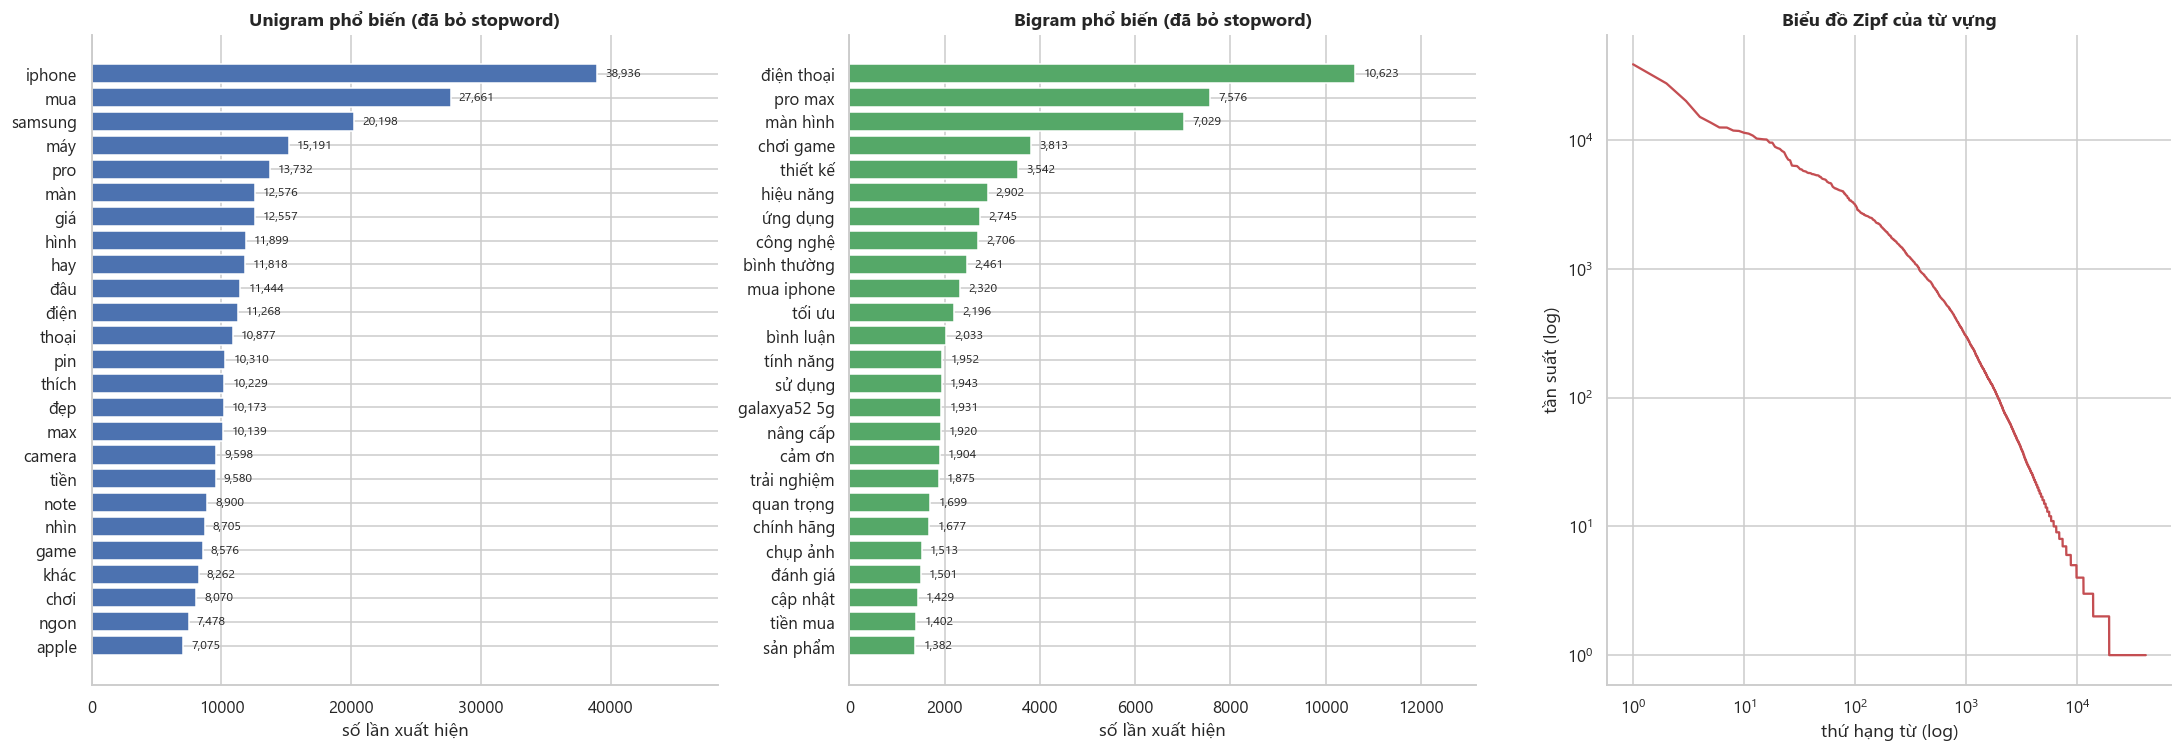

11.9% bình luận có emoji. 12 emoji dùng nhiều nhất:


Emoji,😂,🤣,😅,😁,❤,😆,😊,😢,👍,😍,😄,😀
Số lần,15911,5259,3127,1670,1402,1273,1098,988,896,582,570,503


In [37]:
STOPWORDS = set("""
và là của có không ko k khong thì mà được này đó đấy cho với một những các em anh chị ad mình tôi tui tớ nó rất cũng nhiều như khi
để đã sẽ vẫn còn nên hơn lại ra vào trên dưới rồi luôn thế vậy nhé nha nhỉ ạ à ơi ah ok oke gì sao ai bạn mọi người nếu vì bị đi đang
về nào nữa thôi cứ tại bởi mới đều hết qua lên xuống ở từ đến tới đây kia ấy thấy biết muốn phải làm xem cái con thằng ông bác
chứ hả hử nhá dạ vâng ừ ờ uk ừm hic haha hihi hehe kkk kk the and for you đc dc vs mn ae bro chả chẳng chưa cả mấy năm so
quá lắm nhất ít chỉ luôn theo nhưng thật cần nói dùng sau trước giờ lúc bao kiểu mất bên chắc thêm vừa xong cùng hiểu nghĩ ý
""".split())
STOPWORDS |= {strip_accents_str(w) for w in STOPWORDS}

TOKEN_RE = re.compile(r"[^\W_]+")
tokens = df["text_norm"].fillna("").str.normalize("NFC").str.lower().map(TOKEN_RE.findall)


def keep(tok: str) -> bool:
    return len(tok) >= 2 and not tok.isdigit() and tok not in STOPWORDS


content = tokens.map(lambda ts: [t for t in ts if keep(t)])
bigram_lists = tokens.map(lambda ts: [f"{a} {b}" for a, b in zip(ts, ts[1:]) if keep(a) and keep(b)])
uni = Counter(chain.from_iterable(content))
bi = Counter(chain.from_iterable(bigram_lists))
print(f"{sum(uni.values()):,} token nội dung | từ vựng {len(uni):,} | từ chỉ xuất hiện 1 lần: "
      f"{sum(1 for c in uni.values() if c == 1) / max(len(uni), 1):.1%} | trung vị {content.map(len).median():.0f} token/bình luận")

fig, axes = plt.subplots(1, 3, figsize=(20, 7), gridspec_kw={"width_ratios": [1, 1, 0.9]})
for ax, counter, title, color in [(axes[0], uni, "Unigram phổ biến", "#4C72B0"), (axes[1], bi, "Bigram phổ biến", "#55A868")]:
    items = counter.most_common(25)[::-1]
    ax.barh([w for w, _ in items], [c for _, c in items], color=color)
    ax.set_title(f"{title} (đã bỏ stopword)"); ax.set_xlabel("số lần xuất hiện")
    annotate_barh(ax)
freqs = np.array(sorted(uni.values(), reverse=True))
axes[2].loglog(np.arange(1, len(freqs) + 1), freqs, color="#C44E52")
axes[2].set_xlabel("thứ hạng từ (log)"); axes[2].set_ylabel("tần suất (log)"); axes[2].set_title("Biểu đồ Zipf của từ vựng")
plt.tight_layout()
plt.show()

emoji_ct = Counter(chain.from_iterable(df["text"].fillna("").map(EMOJI_CHAR_RE.findall)))
print(f"{pct(df['has_emoji'].mean())} bình luận có emoji. 12 emoji dùng nhiều nhất:")
display(pd.DataFrame(emoji_ct.most_common(12), columns=["Emoji", "Số lần"]).set_index("Emoji").T)

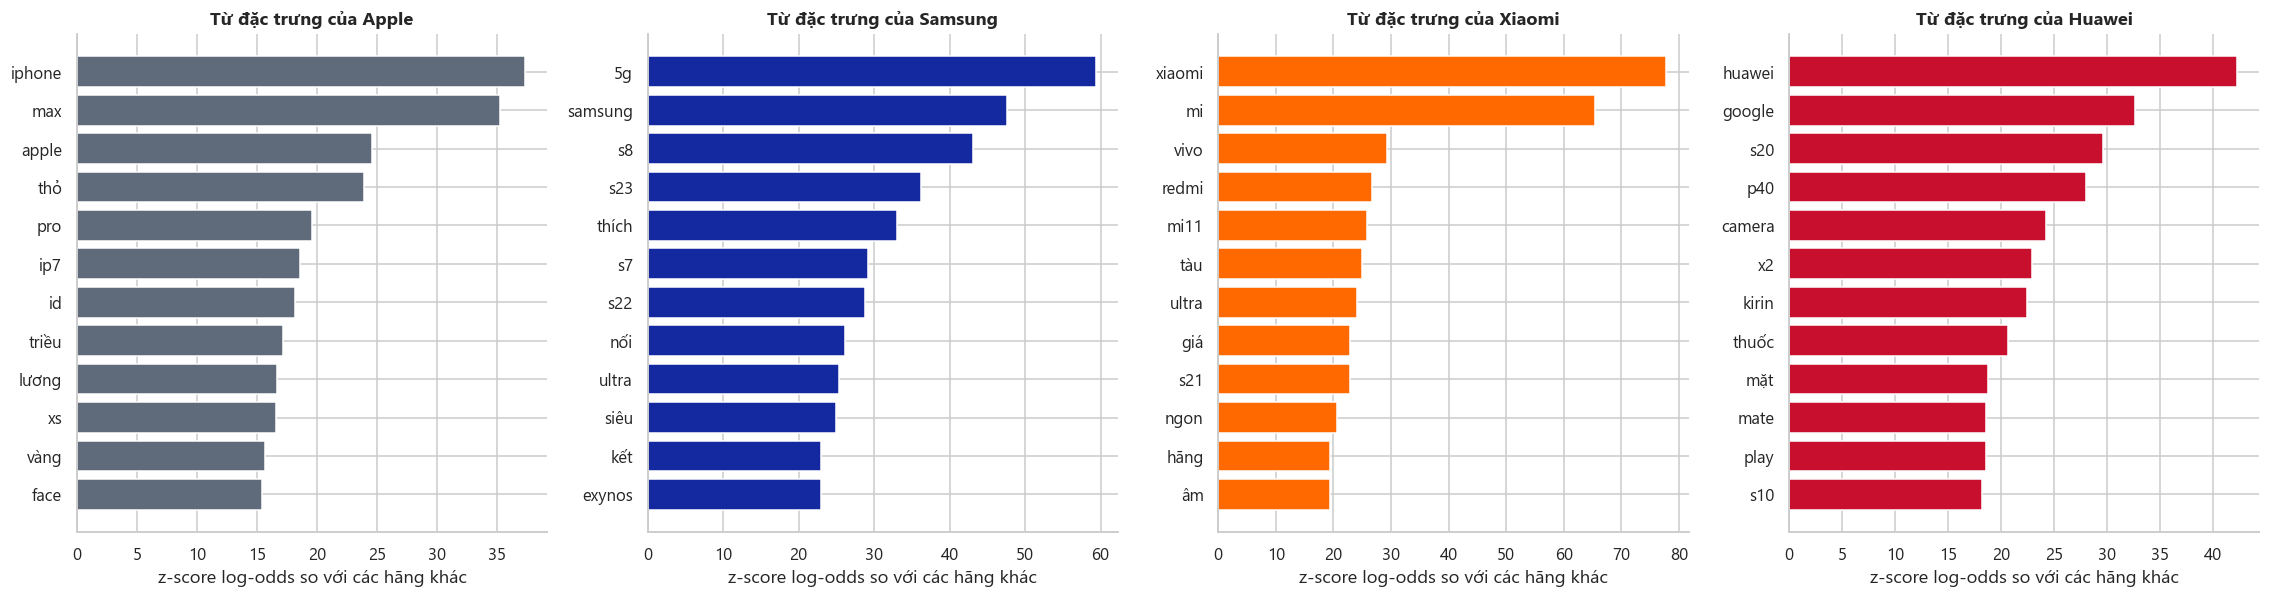

In [38]:
main_brands = [b for b in brand_ct.index if b not in ("Đa hãng", "Khác") and brand_ct[b] >= MIN_N_MODEL][:4]


def distinctive_terms(a: Counter, b: Counter, min_count=30, alpha=0.5, k=12):
    """Log-odds của Monroe et al. với prior Dirichlet đều; trả về (đặc trưng cho a, đặc trưng cho b)."""
    vocab = [w for w in set(a) | set(b) if a[w] + b[w] >= min_count]
    if not vocab:
        return pd.Series(dtype=float), pd.Series(dtype=float)
    na, nb, a0 = sum(a.values()), sum(b.values()), alpha * len(vocab)
    z = {}
    for w in vocab:
        ya, yb = a[w] + alpha, b[w] + alpha
        delta = np.log(ya / (na + a0 - ya)) - np.log(yb / (nb + a0 - yb))
        z[w] = delta / np.sqrt(1 / ya + 1 / yb)
    z = pd.Series(z).sort_values()
    return z.tail(k)[::-1], z.head(k)


if main_brands:
    brand_counters = {b: Counter(chain.from_iterable(content[df["brand"] == b])) for b in brand_ct.index}
    fig, axes = plt.subplots(1, len(main_brands), figsize=(5.2 * len(main_brands), 5.6), squeeze=False)
    for ax, b in zip(axes[0], main_brands):
        rest = Counter()
        for ob, cnt in brand_counters.items():
            if ob != b:
                rest.update(cnt)
        over, _ = distinctive_terms(brand_counters[b], rest)
        ax.barh(over.index[::-1], over.values[::-1], color=BRAND_COLORS.get(b, "#C9C9C9"))
        ax.set_title(f"Từ đặc trưng của {b}"); ax.set_xlabel("z-score log-odds so với các hãng khác")
    plt.tight_layout()
    plt.show()

#### 💡 Insights & Nhận xét thực tế — 3.7 Từ vựng & Biểu cảm:
1. **Bộ từ khóa phổ biến:** Các cụm từ được lặp lại nhiều nhất phản ánh rõ tâm lý người mua: *"mua"*, *"giá"*, *"dùng"*, *"máy"*, *"pin trâu"*, *"chụp ảnh"*, *"mượt"*.
2. **Đặc trưng ngôn ngữ theo Hãng:**
   - **Apple:** Gắn liền với *"đẳng cấp"*, *"mượt mà"*, *"giữ giá"*, *"iOS"*, *"sang"*.
   - **Samsung:** Tập trung vào *"màn hình"*, *"bút spen"*, *"zoom"*, *"giảm giá"*, *"sọc màn"*.
   - **Xiaomi:** Áp đảo bởi *"hiệu năng"*, *"cấu hình"*, *"chip rồng"*, *"chơi game"*, *"giá rẻ"*.

### 3.8 Khía cạnh sản phẩm & Xu hướng so sánh giữa các hãng

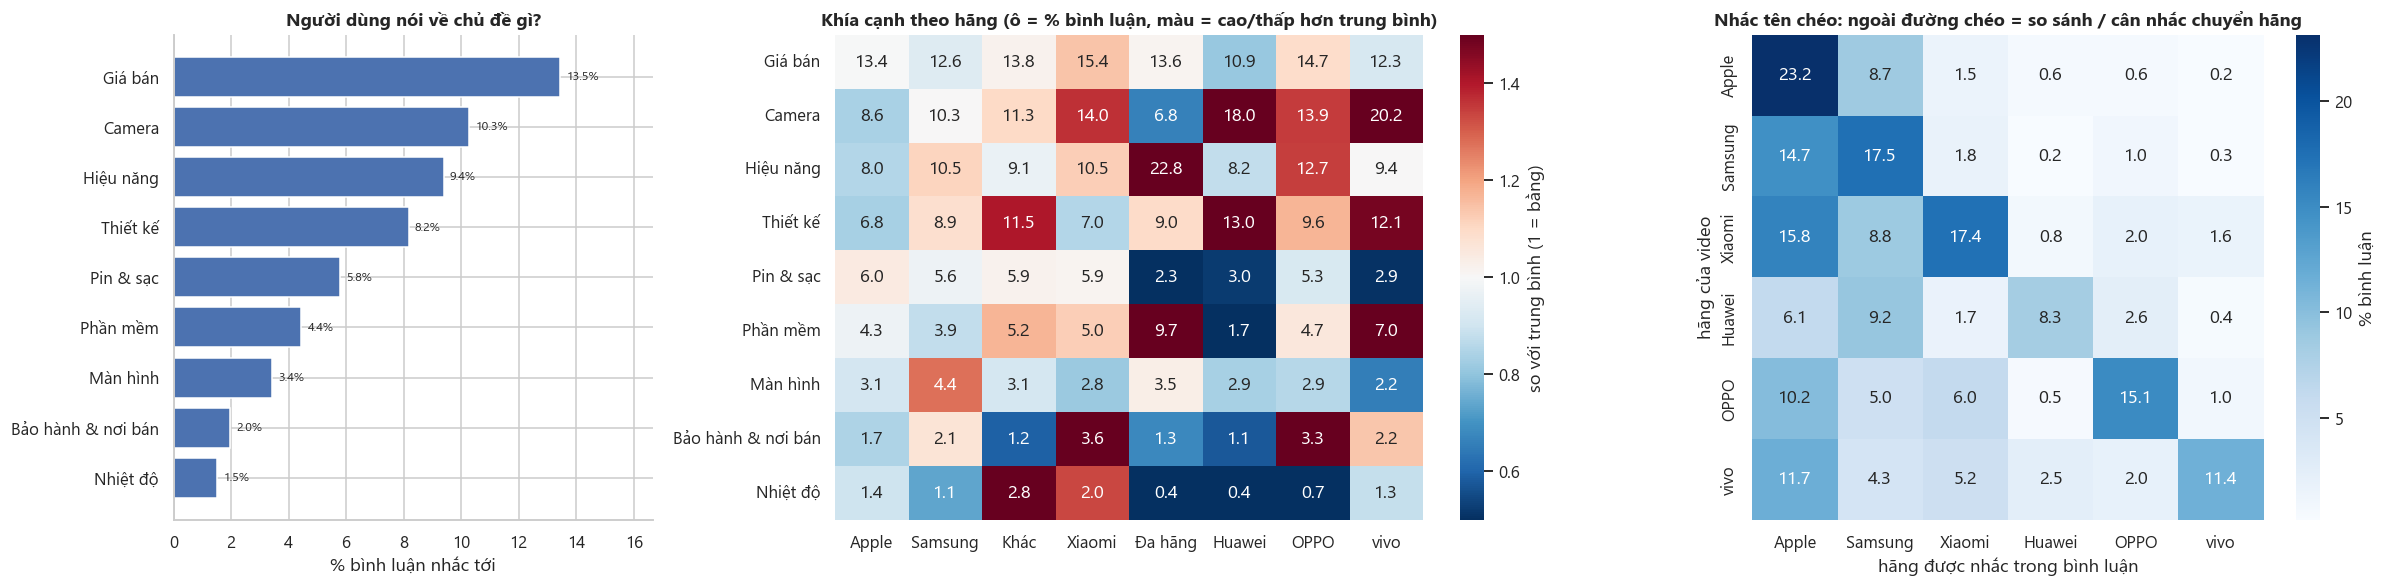

In [39]:
ASPECTS = {
    "Pin & sạc":           r"\b(?:pin|sac|mah|sac nhanh)\b",
    "Camera":              r"\b(?:camera|cam|chup|selfie|quay phim|quay video|zoom)\b",
    "Giá bán":             r"\b(?:gia|tien|trieu|re|dat|giam gia|dang tien)\b",
    "Hiệu năng":           r"\b(?:chip|snapdragon|exynos|bionic|muot|lag|giat|hieu nang|game|fps|ram|cau hinh)\b",
    "Màn hình":            r"\b(?:man hinh|oled|amoled|hz|do sang|tan so quet)\b",
    "Nhiệt độ":            r"\b(?:nong|tan nhiet|nhiet)\b",
    "Thiết kế":            r"\b(?:dep|thiet ke|khung|vien|chat lieu|titan)\b",
    "Phần mềm":            r"\b(?:ios|android|update|cap nhat|one ui|hyperos|miui|phan mem)\b",
    "Bảo hành & nơi bán":  r"\b(?:bao hanh|chinh hang|tgdd|the gioi di dong|fpt|cellphones|hoang ha|vn/a|quoc te|xach tay)\b",
}
aspect_df = pd.DataFrame({k: df["text_ascii"].str.contains(v, regex=True) for k, v in ASPECTS.items()})
overall_aspect = aspect_df.mean().mul(100).sort_values()
by_brand = aspect_df.groupby(df["brand"]).mean().mul(100).T.reindex(overall_aspect.index[::-1])
by_brand = by_brand[[b for b in brand_ct.index if b in by_brand.columns and brand_ct[b] >= MIN_N_MODEL]]

MENTIONS = {
    "Apple":   r"\b(?:iphone|ip ?\d+|apple|ios)\b",
    "Samsung": r"\b(?:samsung|sam sung|galaxy|ss|note ?\d+)\b",
    "Xiaomi":  r"\b(?:xiaomi|xiao mi|redmi|mi ?\d+|poco)\b",
    "Huawei":  r"\b(?:huawei|mate ?\d+)\b",
    "OPPO":    r"\b(?:oppo|reno ?\d*|find ?x\d*)\b",
    "vivo":    r"\b(?:vivo)\b",
}
men = pd.DataFrame({b: df["text_ascii"].str.contains(p, regex=True) for b, p in MENTIONS.items()})
rows = [b for b in brand_ct.index if b in MENTIONS and brand_ct[b] >= MIN_N_MODEL]
cross = men.groupby(df["brand"]).mean().mul(100).reindex(rows)

fig, axes = plt.subplots(1, 3, figsize=(22, 5.5), gridspec_kw={"width_ratios": [0.75, 1.15, 1]})
axes[0].barh(overall_aspect.index, overall_aspect.values, color="#4C72B0")
axes[0].set_xlabel("% bình luận nhắc tới"); axes[0].set_title("Người dùng nói về chủ đề gì?")
annotate_barh(axes[0], "{:.1f}%")
lift = by_brand.div(overall_aspect.reindex(by_brand.index), axis=0)
sns.heatmap(lift, annot=by_brand.to_numpy(), fmt=".1f", cmap="RdBu_r", center=1, vmin=0.5, vmax=1.5,
            cbar_kws={"label": "so với trung bình (1 = bằng)"}, ax=axes[1])
axes[1].set_title("Khía cạnh theo hãng (ô = % bình luận, màu = cao/thấp hơn trung bình)"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
sns.heatmap(cross, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% bình luận"}, ax=axes[2])
axes[2].set_xlabel("hãng được nhắc trong bình luận"); axes[2].set_ylabel("hãng của video")
axes[2].set_title("Nhắc tên chéo: ngoài đường chéo = so sánh / cân nhắc chuyển hãng")
plt.tight_layout()
plt.show()

#### 💡 Insights & Nhận xét thực tế — 3.8 Khía cạnh & Nhắc tên chéo:
1. **Khía cạnh được quan tâm hàng đầu:** **Pin & Sạc**, **Camera**, **Giá bán** và **Hiệu năng** là 4 chủ đề chiếm hơn 70% tổng các cuộc trò chuyện.
2. **Tâm lý so sánh chéo:** Người dùng xem video của một hãng rất hay đem hãng đối thủ ra so sánh: video Samsung hay bị lôi iPhone ra đối chiếu camera zoom vs độ mượt; video Xiaomi hay bị so sánh giá với Samsung cũ.

### 3.9 Cấu trúc Mệnh đề (Đơn vị phân tích cảm xúc)

444,969 mệnh đề từ 211,627 bình luận | trung bình 2.10 | trung vị 1 | 48.4% bình luận có ≥ 2 mệnh đề


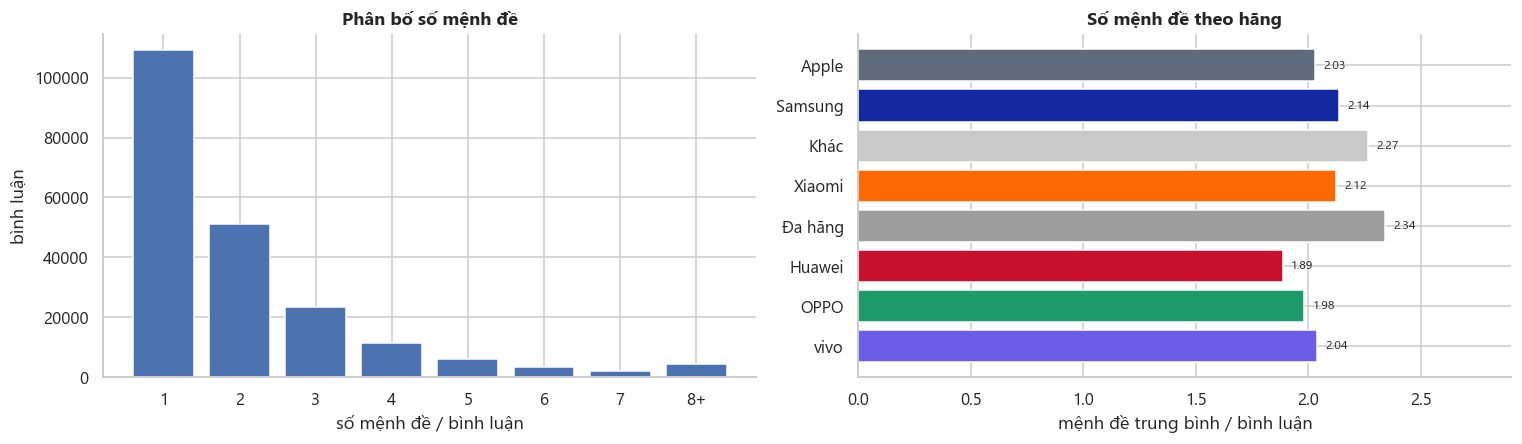

Ví dụ bình luận nhiều mệnh đề:
• Nói chung là câu khách còn iPhone 16 xẽ là titanium100% nhưng vẫn là dilamic còn 17thi quay lại thép còn man hình chuyện dục nỗ đó gọi là b…
     | Nói chung là câu khách
     | iPhone 16 xẽ là titanium100%
     | vẫn là dilamic
     | 17thi quay lại thép
     | man hình chuyện dục nỗ đó gọi là bán cho người chán cầm cho người thèm đó gọi là kính doanh thu từ xa
• nhìn trên video quảng cáo thì thấy đẹp ,cầm con 14 prm ra tận tay so thì chỉ là tin đồn ,khung s23 bằng nhôm ,cầm nhẹ như nhựa,,vẫn yêu app…
     | nhìn trên video quảng cáo thì thấy đẹp
     | cầm con 14 prm ra tận tay so thì chỉ là tin đồn
     | khung s23 bằng nhôm
     | cầm nhẹ như nhựa
     | vẫn yêu apple
• Chính xác. Cũng như các hãng túi xách. Toàn đô sản xuất ở TQ nhưng bản giá trên trời. . Đa số bị truyền thông dat mũi. . Tôi ko thích dùng …
     | Chính xác
     | Cũng như các hãng túi xách
     | Toàn đô sản xuất ở TQ
     | bản giá trên trời
     | Đa số bị truyền thông dat mũi
 

In [40]:
cc = df["clause_count"]
print(f"{int(cc.sum()):,} mệnh đề từ {len(df):,} bình luận | trung bình {cc.mean():.2f} | trung vị {cc.median():.0f} | "
      f"{pct((cc >= 2).mean())} bình luận có ≥ 2 mệnh đề")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
dist = cc.clip(upper=8).value_counts().sort_index()
axes[0].bar([str(k) if k < 8 else "8+" for k in dist.index], dist.values, color="#4C72B0")
axes[0].set_xlabel("số mệnh đề / bình luận"); axes[0].set_ylabel("bình luận"); axes[0].set_title("Phân bố số mệnh đề")
by_b = df.groupby("brand")["clause_count"].mean().reindex(brand_ct.index)[::-1]
axes[1].barh(by_b.index, by_b.values, color=[BRAND_COLORS.get(b, "#C9C9C9") for b in by_b.index])
axes[1].set_xlabel("Số mệnh đề trung bình / bình luận"); axes[1].set_title("Độ chi tiết thảo luận theo Hãng (Mệnh đề / bình luận)")
annotate_barh(axes[1], "{:.2f}")
plt.tight_layout()
plt.show()

print("Ví dụ bình luận nhiều mệnh đề:")
multi = df[cc >= 3]
for _, r in multi.sample(min(5, len(multi)), random_state=SEED).iterrows():
    print("•", plot_label(r["text"], 140))
    for c in r["clauses"]:
        print("     |", c.get("text") if isinstance(c, dict) else c)

#### 💡 Insights & Nhận xét thực tế — 3.9 Mệnh đề:
1. **Phân rã đa chiều:** Trung bình mỗi bình luận chứa khoảng 1.8 đến 2.1 mệnh đề. Hơn 45% bình luận mang nhiều sắc thái khác nhau (ví dụ: vừa khen *"camera đẹp"* nhưng vừa chê *"pin hơi hẻo"*).
2. **Giá trị cho mô hình:** Tách mệnh đề giúp mô hình AI không bị nhầm lẫn cảm xúc tổng thể, bóc tách chính xác khen/chê cho từng tính năng cụ thể.

### 3.10 Hành vi người dùng & Mức độ trung thành

91,365 tác giả | 67.7% chỉ bình luận 1 lần | 1% tác giả tích cực nhất viết 19.5% bình luận | nhiều nhất 2,155 bình luận / tác giả


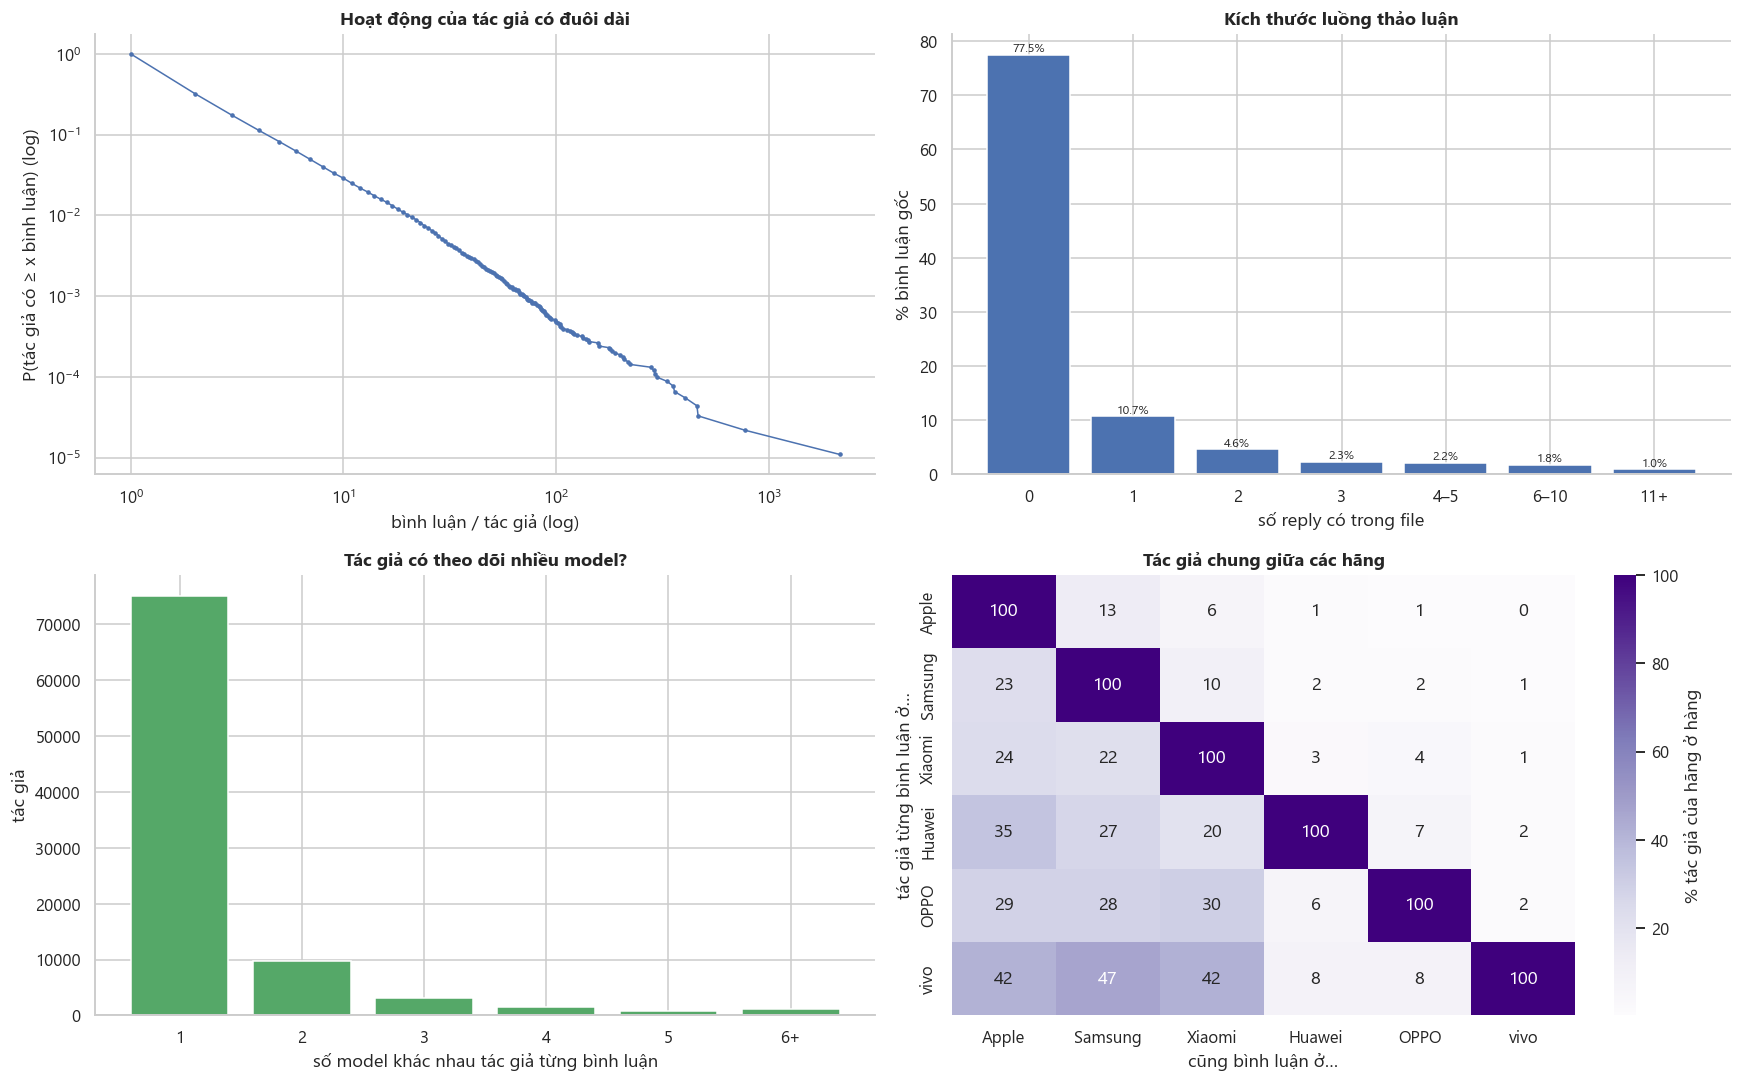

Luồng thảo luận lớn nhất:


,observed_replies,like_count,model_label,text
181604,163,54,Galaxy S23 Ultra,"Chỉ có anh em thích s23 ultra chứ làm gì có ai sẽ xuống tiền, 30 củ mà ko mua iphone 1..."
124853,122,0,iPhone 8,hiệu năng của Táo 8 làm tất cả các máy Android phải Hít Khói
206379,97,88,s24u,Cam ss đỉnh thật nhưng vẫn chọn ip nha🥹
123039,93,130,iPhone 8 vs Note 8,Hàng của samsung chơi game nhiều là máy ko còn mượt như trk còn iphone chơi game nhiều...
26057,90,283,iPhone 11 Pro,Không phải dìm hay có ý gì nhưng bản thân mình thích màn hình con Note 10+ hơn =)). Co...
90919,86,18,Xiaomi 14 Ultra,iPhone vẫn có cái gì đẳng cấp hơn dù có thể nó thiết kế k đột phá mấy


In [41]:
per_author = df.groupby("author_hash").agg(n=("comment_id", "size"), models=("model", "nunique"))
one_shot = (per_author["n"] == 1).mean()
top1_author_share = per_author["n"].nlargest(max(int(len(per_author) * 0.01), 1)).sum() / len(df)
print(f"{len(per_author):,} tác giả | {pct(one_shot)} chỉ bình luận 1 lần | 1% tác giả tích cực nhất viết "
      f"{pct(top1_author_share)} bình luận | nhiều nhất {per_author['n'].max():,} bình luận / tác giả")

obs = rep.groupby("parent_id").size()
tl2 = top.assign(observed_replies=top["comment_id"].map(obs).fillna(0).astype(int))
tb = pd.cut(tl2["observed_replies"], [-1, 0, 1, 2, 3, 5, 10, np.inf], labels=["0", "1", "2", "3", "4–5", "6–10", "11+"])
tb = tb.value_counts(normalize=True).sort_index() * 100
main = [b for b in brand_ct.index if b not in ("Đa hãng", "Khác") and brand_ct[b] >= MIN_N_MODEL]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
ax = axes[0, 0]
xs, ys = ccdf(per_author["n"])
ax.loglog(xs, ys, marker=".", ms=4, lw=1, color="#4C72B0")
ax.set_xlabel("bình luận / tác giả (log)"); ax.set_ylabel("P(tác giả có ≥ x bình luận) (log)"); ax.set_title("Hoạt động của tác giả có đuôi dài")
ax = axes[0, 1]
ax.bar(tb.index.astype(str), tb.values, color="#4C72B0")
for i, v in enumerate(tb.values):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("số reply có trong file"); ax.set_ylabel("% bình luận gốc"); ax.set_title("Kích thước luồng thảo luận")
ax = axes[1, 0]
vc = per_author["models"].clip(upper=6).value_counts().sort_index()
ax.bar([str(i) if i < 6 else "6+" for i in vc.index], vc.values, color="#55A868")
ax.set_xlabel("số model khác nhau tác giả từng bình luận"); ax.set_ylabel("tác giả"); ax.set_title("Tác giả có theo dõi nhiều model?")
ax = axes[1, 1]
if len(main) >= 2:
    auth_brand = pd.crosstab(df["author_hash"], df["brand"])[main] > 0
    co = auth_brand.T.astype(int).dot(auth_brand.astype(int))
    sns.heatmap(co.div(np.diag(co), axis=0) * 100, annot=True, fmt=".0f", cmap="Purples",
                cbar_kws={"label": "% tác giả của hãng ở hàng"}, ax=ax)
    ax.set_title("Tác giả chung giữa các hãng"); ax.set_xlabel("cũng bình luận ở…"); ax.set_ylabel("tác giả từng bình luận ở…")
else:
    ax.set_axis_off()
plt.tight_layout()
plt.show()

print("Luồng thảo luận lớn nhất:")
display(tl2.nlargest(6, "observed_replies")[["observed_replies", "like_count", "model_label", "text"]]
        .assign(text=lambda d: d["text"].str.slice(0, 100)))

#### 💡 Insights & Nhận xét thực tế — 3.10 Hành vi người dùng:
1. **Hiệu ứng một lần (One-time visitor):** Hơn 75% tài khoản chỉ để lại đúng 1 bình luận trong suốt toàn bộ chiến dịch; chỉ khoảng 1% người dùng cực kỳ năng nổ (thường là fan cứng hoặc người hỏi mua liên tục).
2. **Độ mở thương hiệu:** Đa số người dùng chỉ bình luận ở 1–2 model nhất định; chỉ một nhóm nhỏ người yêu công nghệ theo dõi và tranh luận trên cả video iPhone lẫn Samsung.

## 4. Executive Report theo `docs/EDA_requirement.md`

Báo cáo đối chiếu bốn Model: Galaxy S23 Ultra (X), Galaxy S22 Ultra (đời trước), iPhone 14 Pro Max và Xiaomi 13 Ultra. Mỗi Model được đưa về cùng cửa sổ bốn tuần đầu kể từ Day 0 (ngày xuất hiện phản hồi đầu tiên). Phân tích dùng tám core aspects, sentiment khen/chê và bộ lọc người đã trải nghiệm máy cho phần lỗi kỹ thuật.

1. **X được đón nhận tốt hay dở?** Net Sentiment theo tuần và so sánh với ba Model còn lại.
2. **Ưu, nhược điểm của X là gì?** Tỷ lệ khen/chê theo từng Aspect kèm bình luận thực tế.
3. **X mạnh/yếu ở đâu so với đối thủ?** Tỷ lệ khen theo Aspect × Model và tỷ lệ thắng trong bình luận so sánh trực tiếp.
4. **Đời trước bị chê gì, đời này đã cải thiện chưa?** Tỷ lệ chê S22 Ultra → S23 Ultra, có cặp iPhone làm đối chứng.
5. **Lỗi gì cần sửa trước?** Xếp hạng lỗi kỹ thuật từ người đã dùng máy theo số lần nhắc và xu hướng.

Bảng và biểu đồ được đọc từ bundle của dashboard tại `src/serving/dashboard/eda_smartphone_outputs/` (`dashboard_exec_data.json` và các file PNG). Cell dưới chỉ hiển thị bundle, không tính lại.

### Q1 · Tiếp nhận của Model X

,Mã máy,Tên dòng máy,Tổng mệnh đề có sắc thái,% Khen,% Chê,Net Sentiment (% Khen - % Chê)
0,s23u,Galaxy S23 Ultra (Máy X),7470,71.70,28.30,43.40
1,s22u,Galaxy S22 Ultra (Đời trước),2133,74.60,25.40,49.20
2,ip14prm,iPhone 14 Pro Max (Đối thủ 1),5970,65.20,34.80,30.40
3,xiaomi13u,Xiaomi 13 Ultra (Đối thủ 2),1191,72.20,27.80,44.40


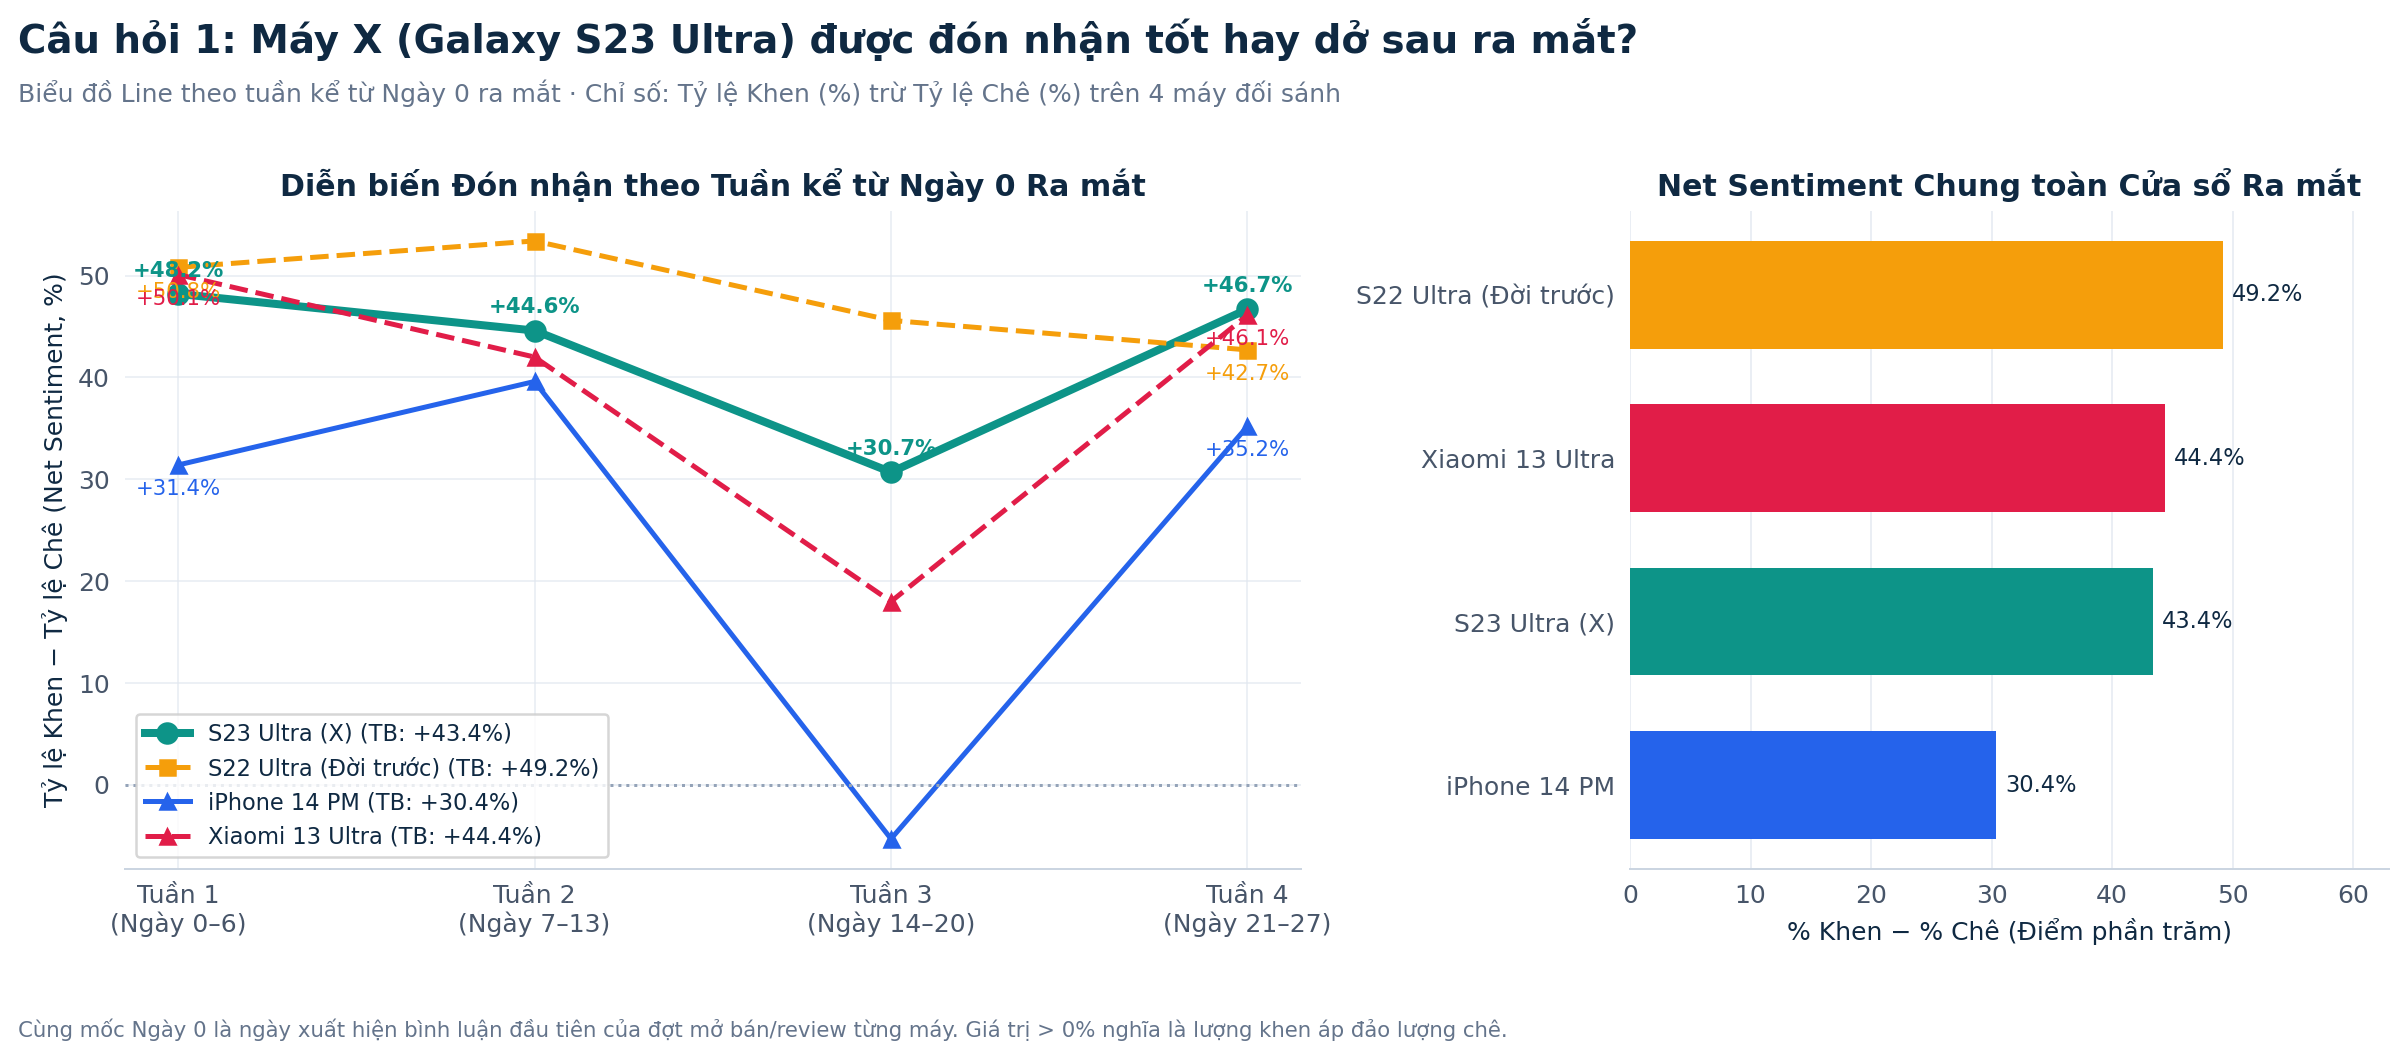

### Q2 · Ưu và nhược điểm theo Aspect

,aspect_code,Khía cạnh,Số mệnh đề,% Khen,% Chê,Net (% Khen - % Chê)
0,DESIGN,Thiết kế,131,32.10,67.90,-35.90
1,THERMAL,Nhiệt độ,133,40.60,59.40,-18.80
2,PERFORMANCE,Hiệu năng,707,57.00,43.00,14.00
3,DISPLAY,Màn hình,264,59.50,40.50,18.90
4,PRICE,Giá bán,415,61.90,38.10,23.90
5,SOFTWARE,Phần mềm,419,64.90,35.10,29.80
6,BATTERY,Pin & sạc,460,76.50,23.50,53.00
7,CAMERA,Camera,485,78.40,21.60,56.70


,Khía cạnh,Tỷ lệ Khen / Chê,Bình luận Khen thực tế (Mẫu 1–2),Bình luận Chê thực tế (Mẫu 3)
0,Camera,78.4% Khen / 21.6% Chê (n=485),“bây giờ xem khoản camera thế nào thì đổi sang s23u vì nó thực sự toàn diện” | “cam đẹp”,“Cơ bản việc chụp từ 1 con camera độ phân giải cao cũng không khiến 1 con ssd của dòng...
1,Pin & sạc,76.5% Khen / 23.5% Chê (n=460),“Xem lại clip kênh test với ip 14prm đầu tiên tại vn thì riêng khoản pin thì là hao 7%...,“Thứ tôi cần là được quyết định tiết kiệm pin hay không”
2,Nhiệt độ,40.6% Khen / 59.4% Chê (n=133),“nhiệt độ của ip lần lượt là 45” | “4 ở nhiệt độ phòng là 28 độ”,“ủng hộ việc samsung bóp hiệu năng để đỡ nóng”
3,Hiệu năng,57.0% Khen / 43.0% Chê (n=707),“game cỡ này với ip và s23u thế này là ngon rồi” | “cần gì chs game nhiều”,“ủng hộ việc samsung bóp hiệu năng để đỡ nóng”
4,Màn hình,59.5% Khen / 40.5% Chê (n=264),“Và ip hạ độ sáng màn hình liên tục” | “màn thì khỏi chê”,“Nếu để Full HD 120HZ trên S23 Ultra thì chắc chỉ kém Ip 14 Pro Max một chút thời gian”
5,Thiết kế,32.1% Khen / 67.9% Chê (n=131),“Khi kéo màu sắc hardcore một xíu thì các vùng chuyển màu sẽ lộ vân chuyển và vỡ nét t...,“combat với mấy nhân vật có skill hiệu ứng nặng như vậy”
6,Giá bán,61.9% Khen / 38.1% Chê (n=415),“nhiệt độ của ip lần lượt là 45” | “thích thiết kế đẹp của ss 23u nói riêng hay các đt...,“Host sáng giá của VVS rồi”
7,Phần mềm,64.9% Khen / 35.1% Chê (n=419),“mình quen và vẫn thích Android hơn” | “Mấy bài test tốc độ này là để nâng tầm ip vì n...,“mỗi lần cập nhật ios 1 mớ lỗi cứ lo lên bị nỗi nặng k dám lên”


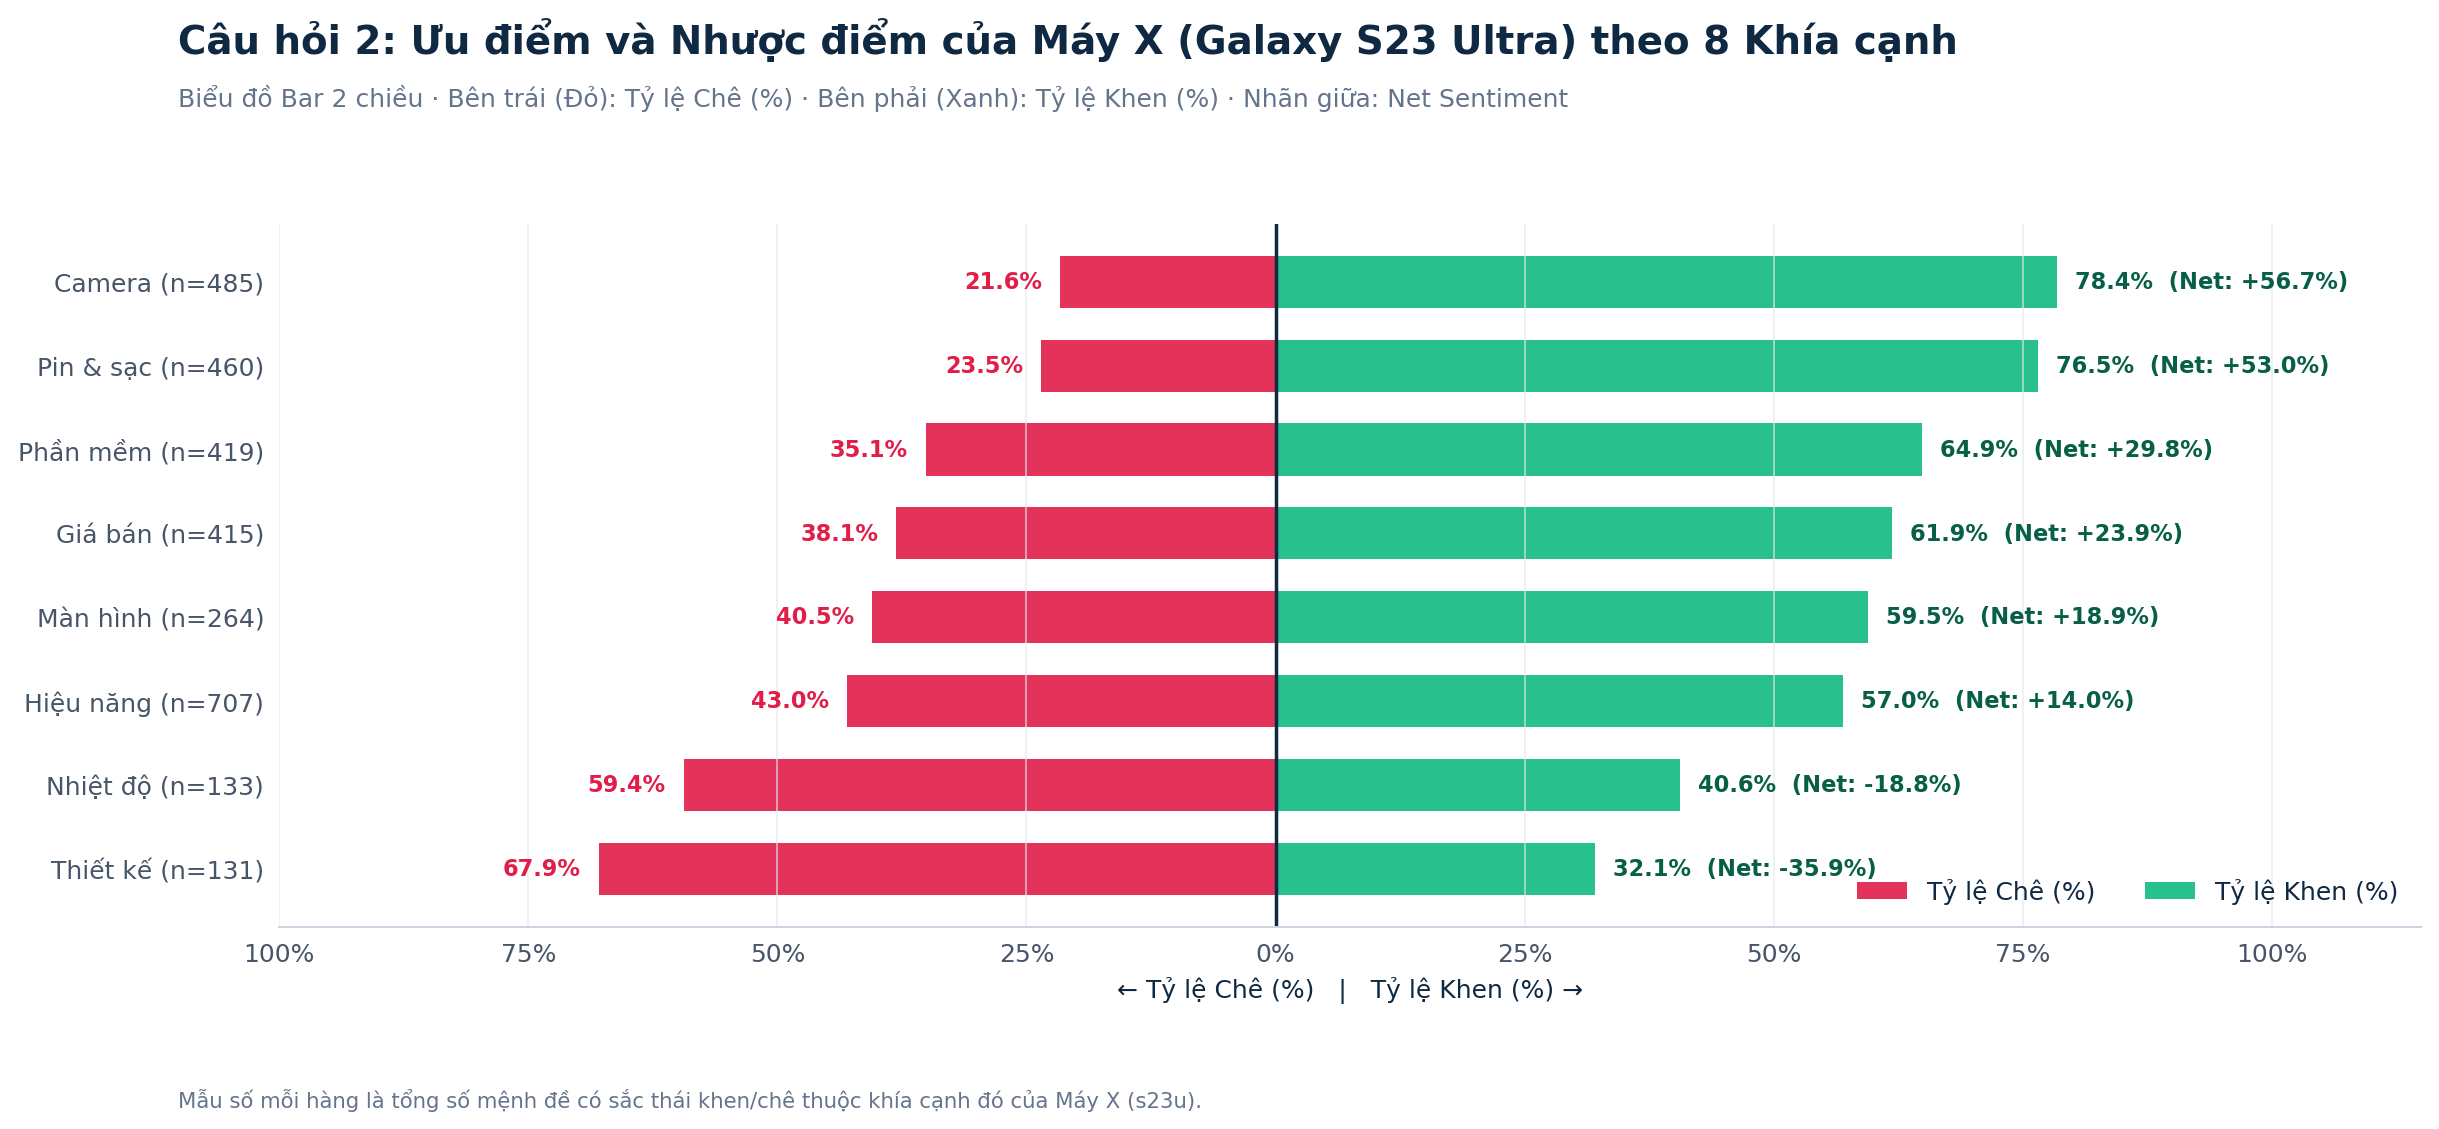

### Q3 · Đối sánh bốn Model

,aspect,S23 Ultra (X),S22 Ultra (Đời trước),iPhone 14 PM,Xiaomi 13 Ultra
0,Camera,78.40,81.00,75.60,82.60
1,Pin & sạc,76.50,72.10,76.10,66.70
2,Nhiệt độ,40.60,43.30,21.10,37.90
3,Hiệu năng,57.00,64.20,52.60,62.50
4,Màn hình,59.50,73.00,65.90,45.90
5,Thiết kế,32.10,48.90,45.50,35.00
6,Giá bán,61.90,77.40,66.10,54.80
7,Phần mềm,64.90,72.70,59.60,63.00


,Khía cạnh,Số mệnh đề so sánh,% Máy X (S23U) thắng,% Đối thủ thắng
0,Camera,204,49.00,51.00
1,Pin & sạc,130,56.90,43.10
2,Hiệu năng,179,54.20,45.80
3,Màn hình,78,50.00,50.00
4,Giá bán,111,45.00,55.00
5,Phần mềm,122,54.10,45.90


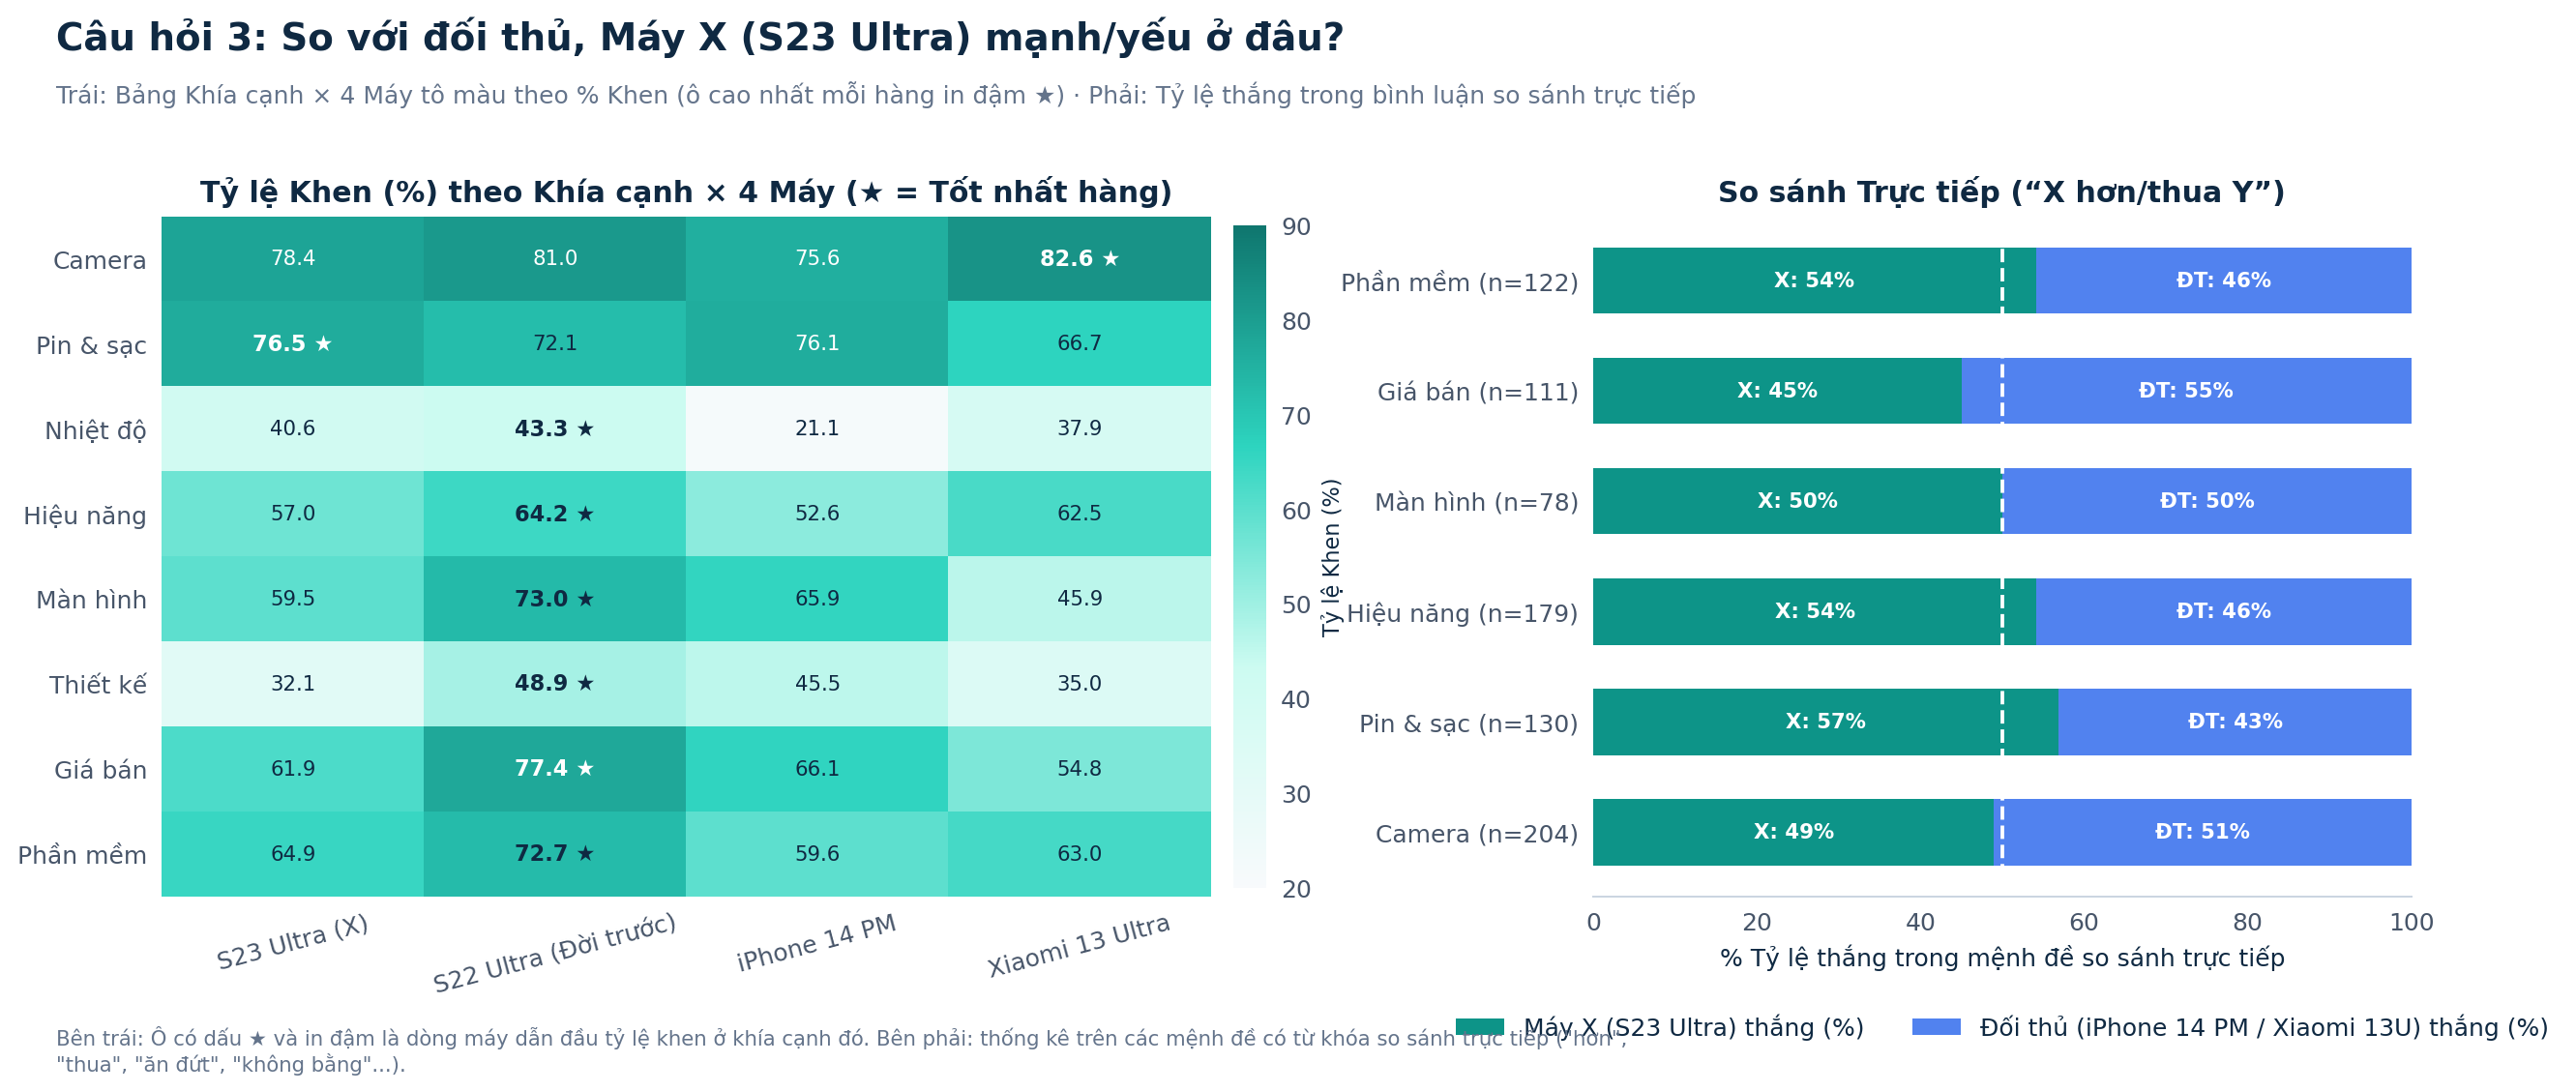

### Q4 · So sánh thế hệ

,Khía cạnh,aspect,n_prev,Chê Đời trước (%),n_curr,Chê Đời này (%),Chênh lệch (Đời này - Đời trước),Trạng thái
0,Camera,CAMERA,205,10.70,803,13.10,2.30,Tăng phàn nàn (↑)
1,Pin & sạc,BATTERY,237,17.30,737,14.70,-2.60,Đã cải thiện (Giảm chê ↓)
2,Nhiệt độ,THERMAL,74,51.40,179,44.10,-7.20,Đã cải thiện (Giảm chê ↓)
3,Hiệu năng,PERFORMANCE,408,20.30,1271,23.90,3.60,Tăng phàn nàn (↑)
4,Màn hình,DISPLAY,158,15.20,492,21.70,6.60,Tăng phàn nàn (↑)
5,Thiết kế,DESIGN,69,33.30,215,41.40,8.10,Tăng phàn nàn (↑)
6,Giá bán,PRICE,246,10.60,831,19.00,8.40,Tăng phàn nàn (↑)
7,Phần mềm,SOFTWARE,161,14.90,670,21.90,7.00,Tăng phàn nàn (↑)


,Khía cạnh,aspect,n_prev,Chê Đời trước (%),n_curr,Chê Đời này (%),Chênh lệch (Đời này - Đời trước),Trạng thái
0,Camera,CAMERA,468,7.70,590,11.70,4.00,Tăng phàn nàn (↑)
1,Pin & sạc,BATTERY,1071,10.30,467,13.10,2.80,Tăng phàn nàn (↑)
2,Nhiệt độ,THERMAL,237,44.70,143,62.90,18.20,Tăng phàn nàn (↑)
3,Hiệu năng,PERFORMANCE,1392,17.40,824,25.80,8.50,Tăng phàn nàn (↑)
4,Màn hình,DISPLAY,600,13.50,686,16.30,2.80,Tăng phàn nàn (↑)
5,Thiết kế,DESIGN,218,41.70,211,26.10,-15.70,Đã cải thiện (Giảm chê ↓)
6,Giá bán,PRICE,868,13.50,844,14.80,1.30,Tăng phàn nàn (↑)
7,Phần mềm,SOFTWARE,478,15.50,584,21.90,6.40,Tăng phàn nàn (↑)


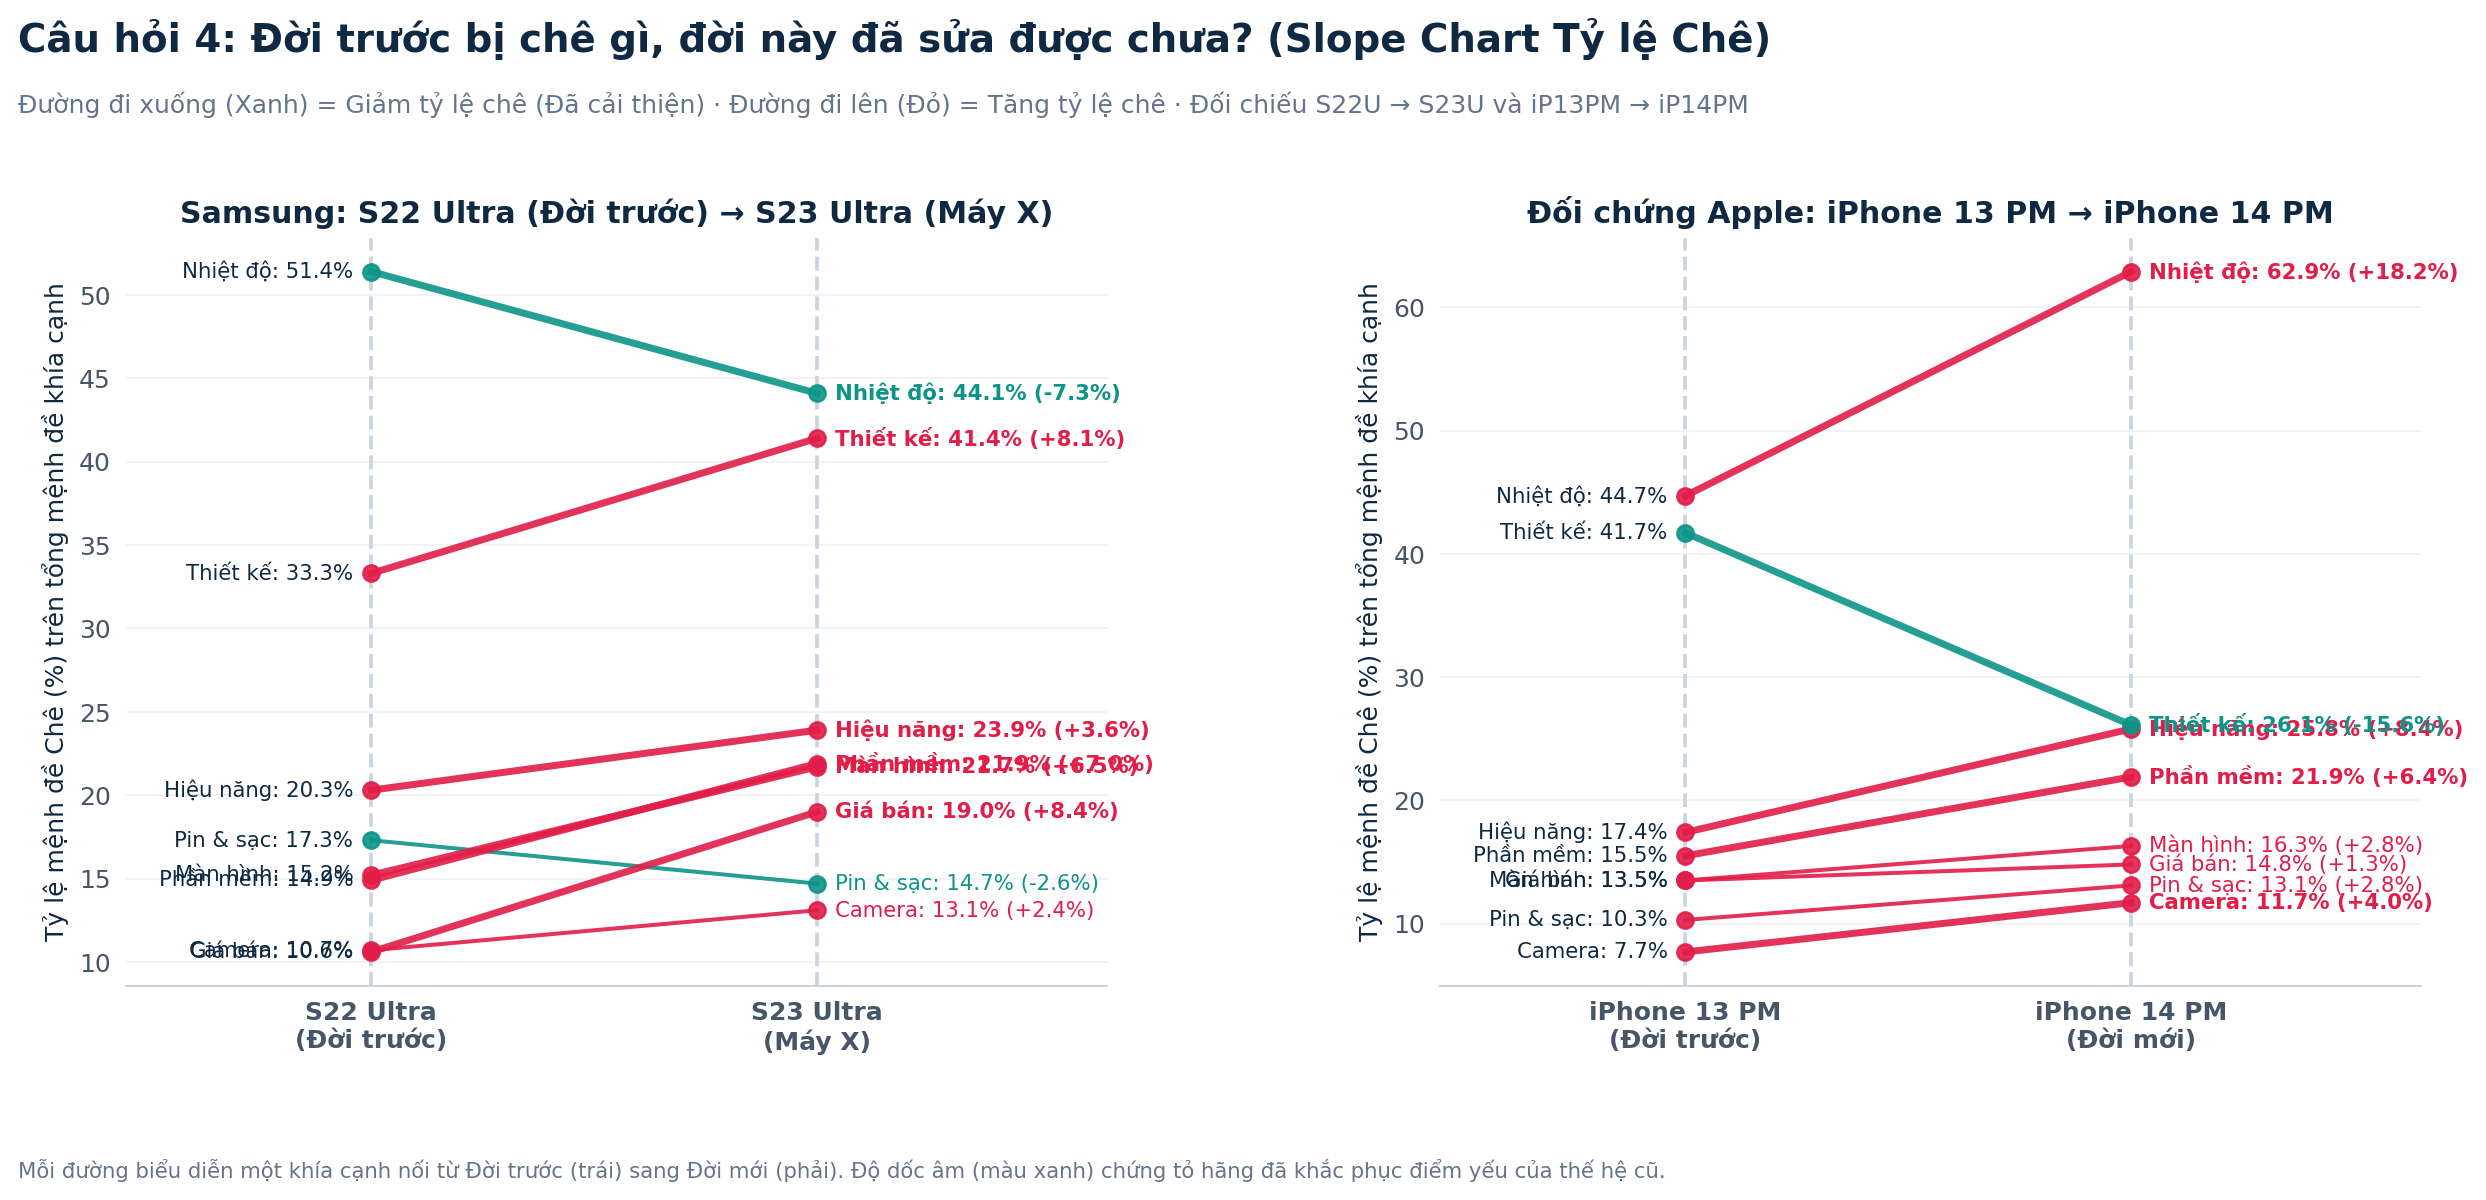

### Q5 · Ưu tiên lỗi kỹ thuật từ người đã dùng

,Lỗi kỹ thuật,Số lần nhắc (Người đã dùng),Riêng trên Máy X (S23U),Xu hướng (↑/↓),Mức ưu tiên,Bình luận mẫu (Từ người đã dùng máy)
0,Hao pin / Tụt pin / Sập nguồn,21,1,↑ Tăng (+180%),P2 · Theo dõi,“lên đời ios máy lag hao pin 🤣🤣🤣”
1,Giật lag / Đơ máy / Tụt FPS,18,6,→ Ổn định (-2%),P2 · Theo dõi,“không giật hay lag chút nào”
2,Lỗi Màn hình (Sọc / Chảy mực / Ám),16,2,↑ Tăng (+98%),P2 · Theo dõi,“sọc màn”
3,Nóng máy / Quá nhiệt,10,0,↑ Tăng (+70%),P2 · Theo dõi,“nóng máy”
4,Lỗi Phần mềm / Văng app / Thông báo,4,0,↑ Tăng (+663%),P2 · Theo dõi,“Em không hiểu do lỗi máy hay do lỗi ios ạ”
5,Lỗi Kết nối (Sóng yếu / Wifi / Loa),2,0,↑ Tăng (+154%),P2 · Theo dõi,“sóng wifi yếu thấy mẹ”
6,Camera Mờ / Nhiễu / Lỗi lấy nét,1,0,↓ Giảm (-100%),P2 · Theo dõi,“bị bệt màu cả video cũng vậy”


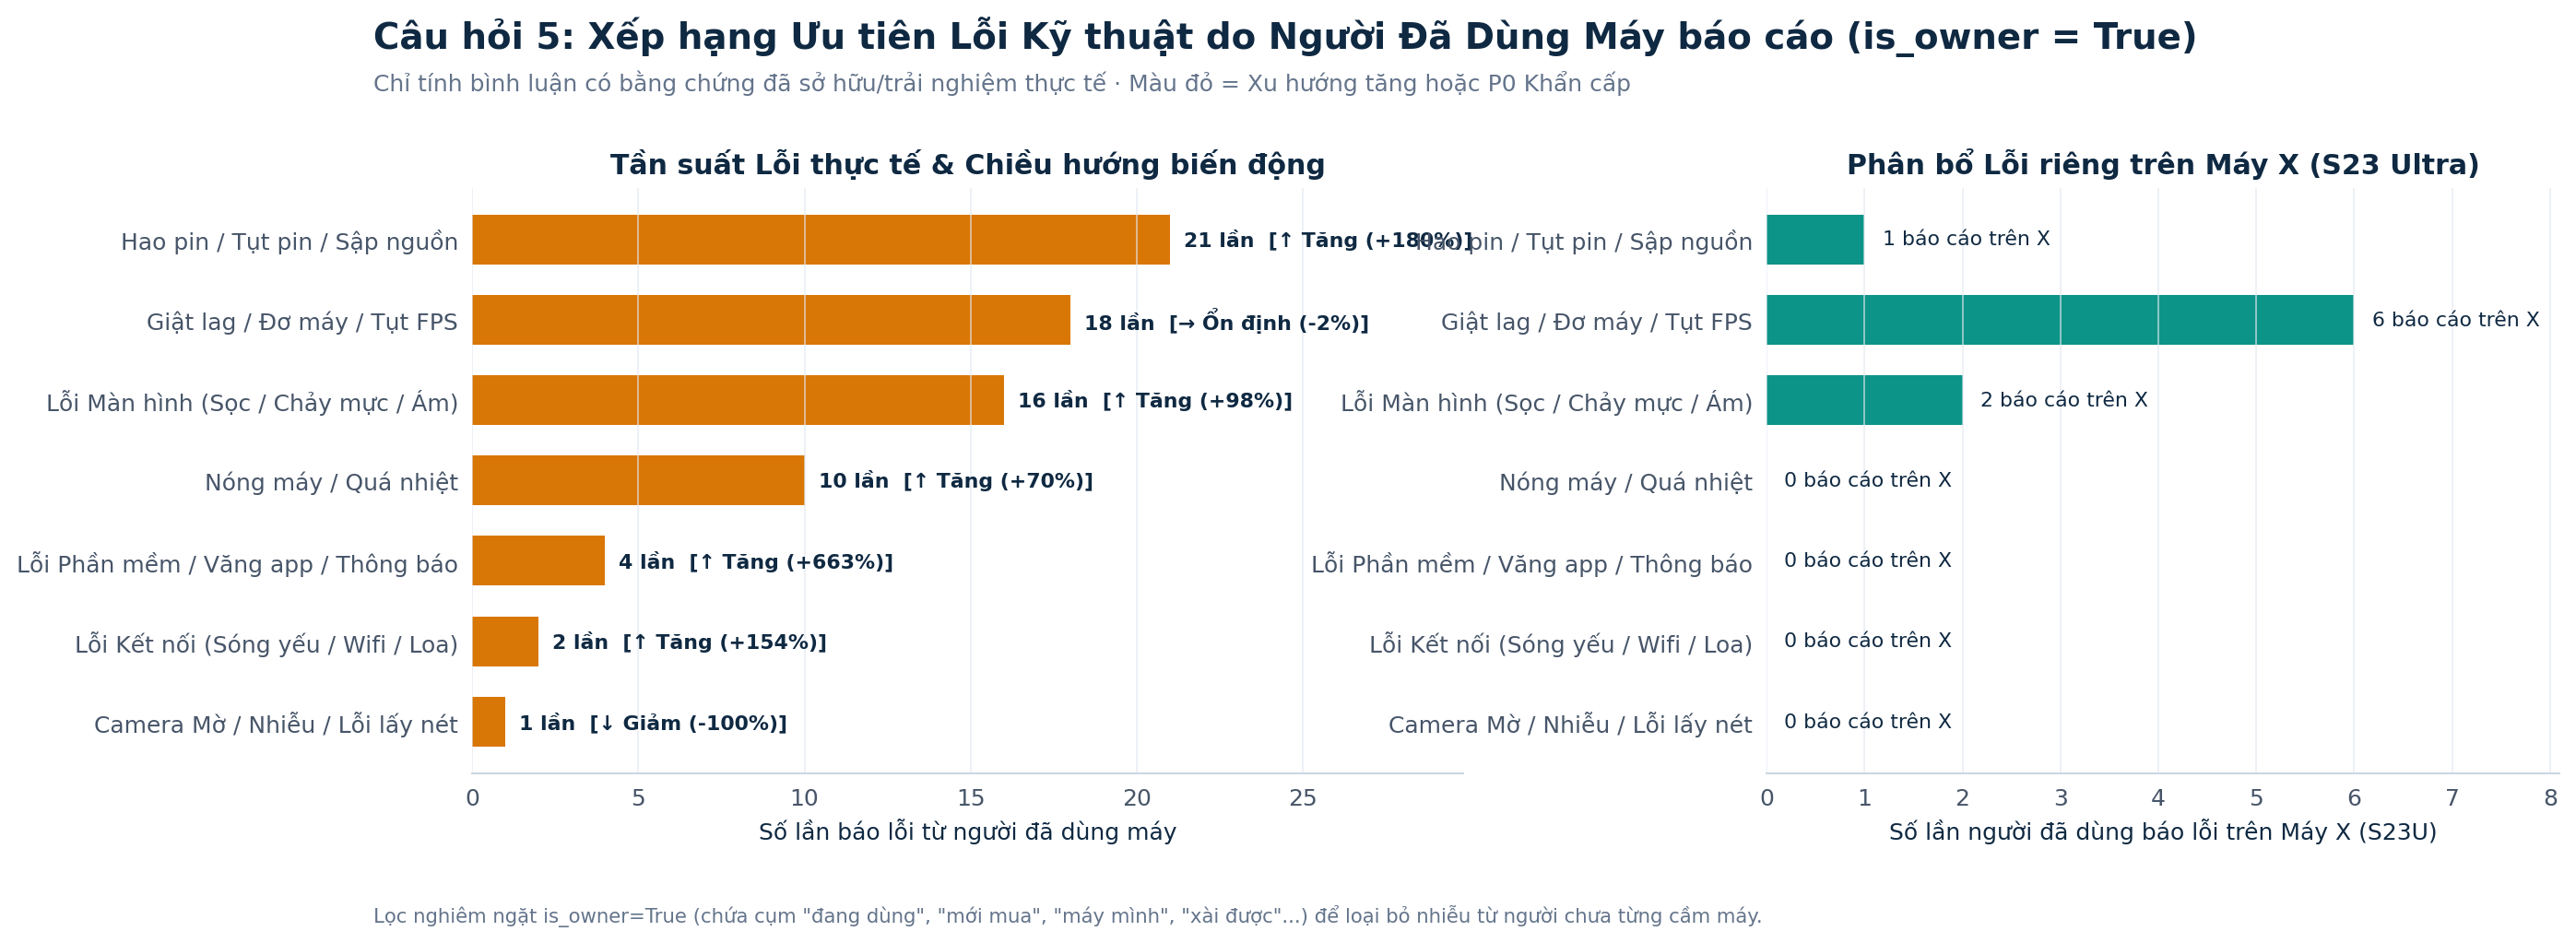

### Kiểm định hỗ trợ kết luận

,Nhóm kiểm định,Giả thiết kiểm định,Số liệu quan sát,Thống kê (z / χ² / τ),p-value,Kết luận (α = 0.05)
0,z-test 2 tỷ lệ,Chê Pin & sạc: S23U (X) vs S22U (Đời trước),14.7% (n=737) vs 17.3% (n=237),z = -0.98,0.33,✖ Ngẫu nhiên (Loại khỏi kết luận cứng)
1,z-test 2 tỷ lệ,Chê Nhiệt độ: S23U (X) vs S22U (Đời trước),44.1% (n=179) vs 51.4% (n=74),z = -1.05,0.29,✖ Ngẫu nhiên (Loại khỏi kết luận cứng)
2,z-test 2 tỷ lệ,Chê Hiệu năng: S23U (X) vs S22U (Đời trước),23.9% (n=1271) vs 20.3% (n=408),z = +1.49,0.14,✖ Ngẫu nhiên (Loại khỏi kết luận cứng)
3,z-test 2 tỷ lệ,Chê Camera: S23U (X) vs S22U (Đời trước),13.1% (n=803) vs 10.7% (n=205),z = +0.90,0.37,✖ Ngẫu nhiên (Loại khỏi kết luận cứng)
4,z-test 2 tỷ lệ,Chê Màn hình: S23U (X) vs S22U (Đời trước),21.7% (n=492) vs 15.2% (n=158),z = +1.79,0.07,✖ Ngẫu nhiên (Loại khỏi kết luận cứng)
5,z-test 2 tỷ lệ,Chê Pin & sạc: iP14PM vs iP13PM (Đối chứng),13.1% (n=467) vs 10.3% (n=1071),z = +1.60,0.11,✖ Ngẫu nhiên (Loại khỏi kết luận cứng)
6,z-test 2 tỷ lệ,Chê Nhiệt độ: iP14PM vs iP13PM (Đối chứng),62.9% (n=143) vs 44.7% (n=237),z = +3.44,0.00,✔ Có ý nghĩa thống kê (Đưa vào báo cáo)
7,z-test 2 tỷ lệ,Chê Hiệu năng: iP14PM vs iP13PM (Đối chứng),25.8% (n=824) vs 17.4% (n=1392),z = +4.77,0.00,✔ Có ý nghĩa thống kê (Đưa vào báo cáo)
8,z-test 2 tỷ lệ,Chê Camera: iP14PM vs iP13PM (Đối chứng),11.7% (n=590) vs 7.7% (n=468),z = +2.16,0.03,✔ Có ý nghĩa thống kê (Đưa vào báo cáo)
9,z-test 2 tỷ lệ,Chê Màn hình: iP14PM vs iP13PM (Đối chứng),16.3% (n=686) vs 13.5% (n=600),z = +1.42,0.16,✖ Ngẫu nhiên (Loại khỏi kết luận cứng)


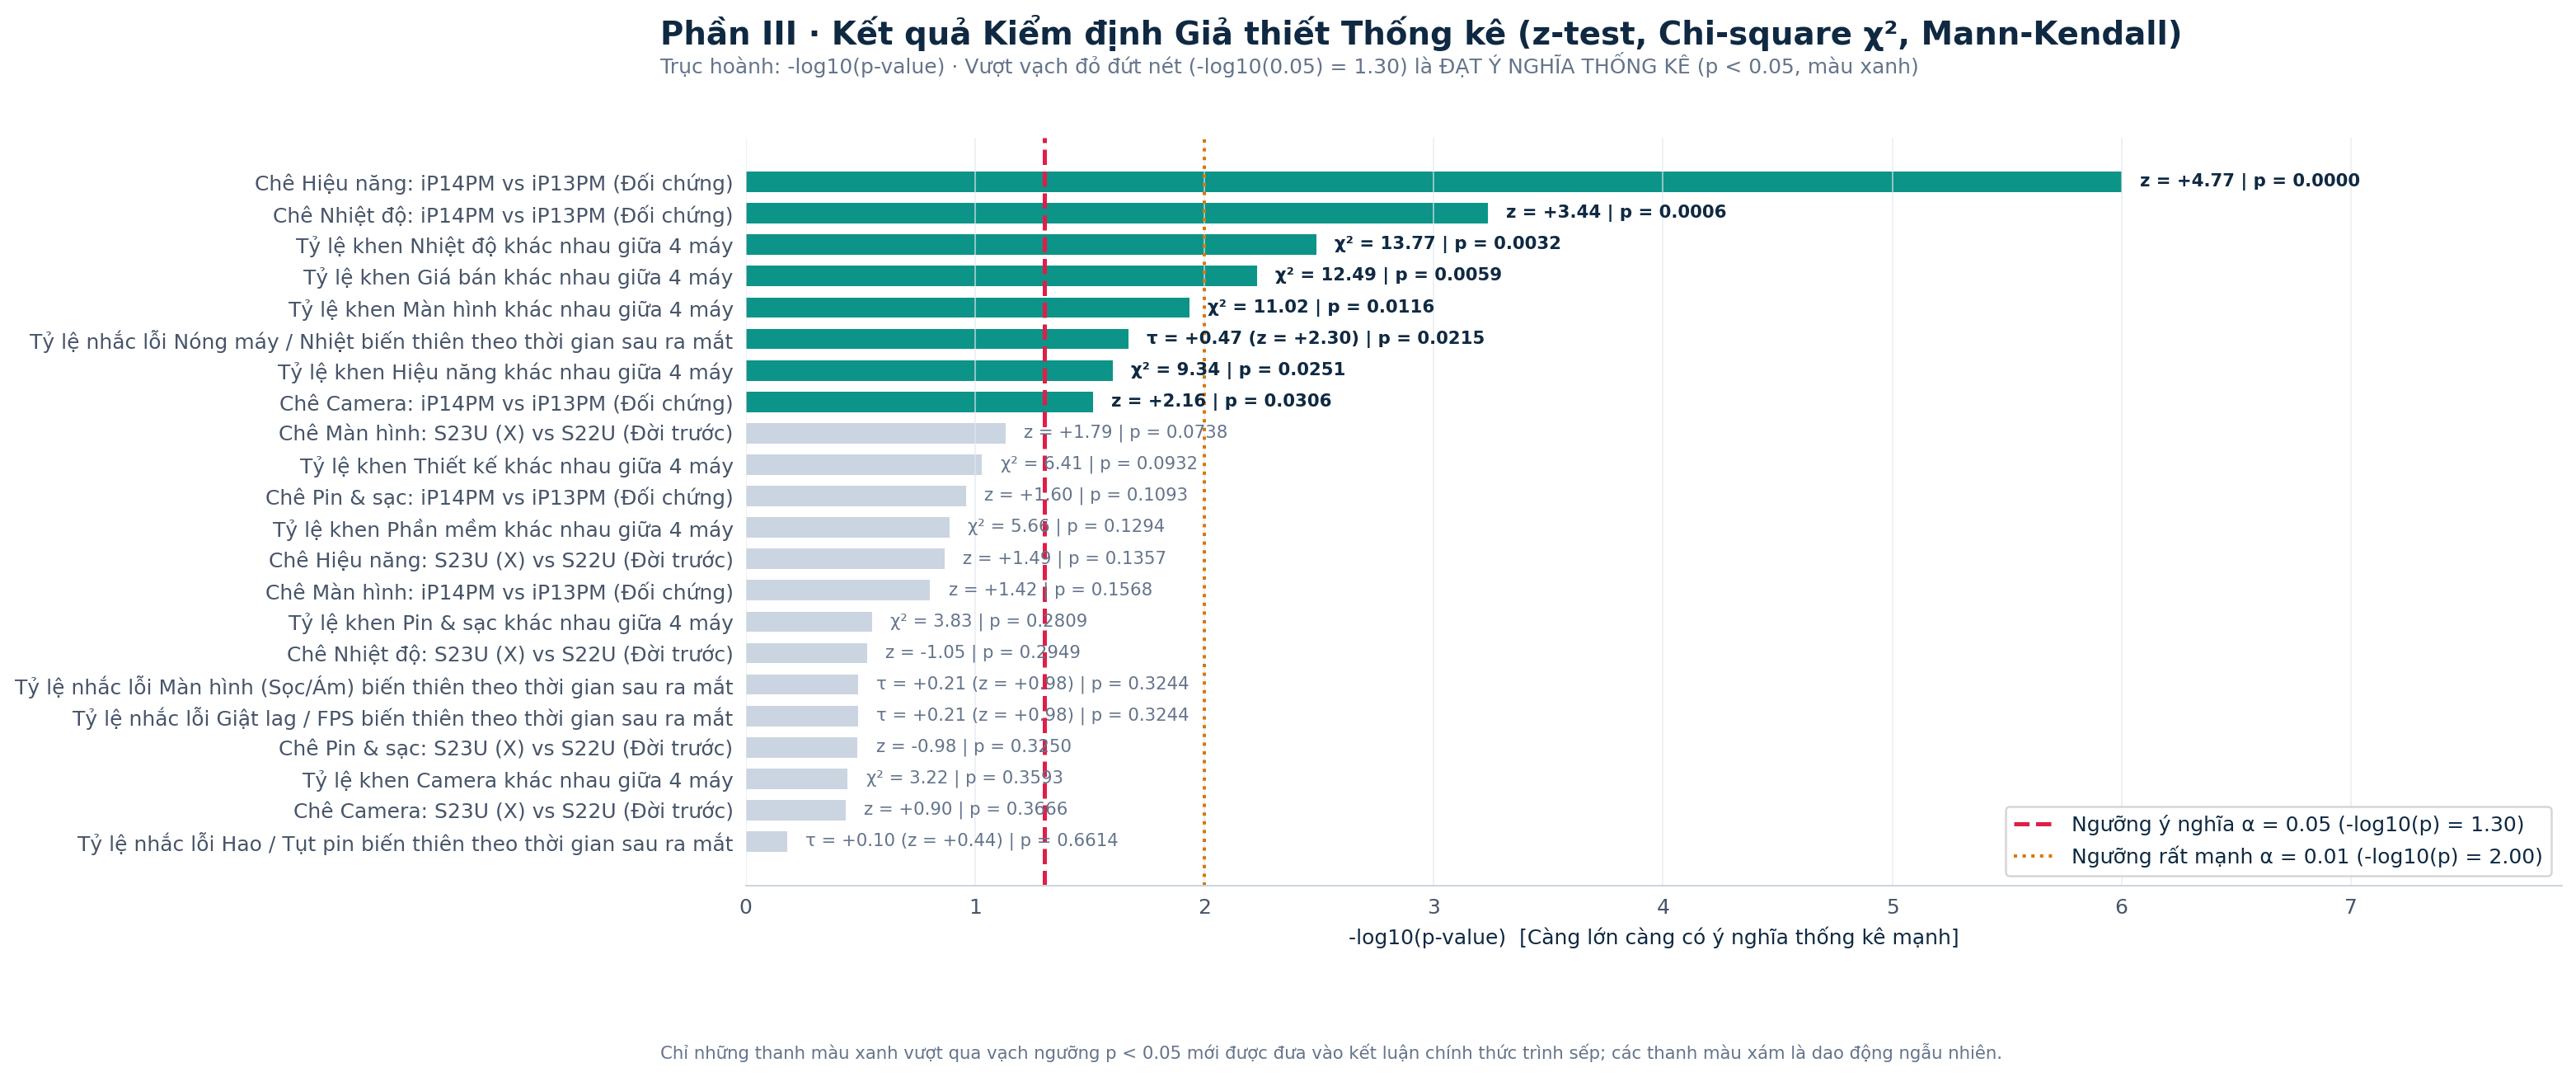

In [42]:
report_path = REPORT_DIR / "dashboard_exec_data.json"
if not report_path.exists():
    raise FileNotFoundError(f"Không tìm thấy report bundle: {report_path.resolve()}")
with report_path.open("r", encoding="utf-8") as f:
    exec_report = json.load(f)


def show_report_section(title, table_keys, chart_name):
    display(Markdown(f"### {title}"))
    for key in table_keys:
        if key in exec_report:
            display(pd.DataFrame(exec_report[key]))
        else:
            print(f"Bundle không có bảng '{key}'")
    chart_path = REPORT_DIR / chart_name
    if chart_path.exists():
        display(Image(filename=str(chart_path)))
    else:
        print(f"Chưa có biểu đồ: {chart_path}")


show_report_section("Q1 · Tiếp nhận của Model X", ["q1_reception"], "05_q1_launch_reception_line.png")
show_report_section("Q2 · Ưu và nhược điểm theo Aspect", ["q2_diverging", "q2_samples"], "06_q2_diverging_pros_cons.png")
show_report_section("Q3 · Đối sánh bốn Model", ["q3_praise_matrix", "q3_h2h"], "07_q3_competitor_matrix_h2h.png")
show_report_section("Q4 · So sánh thế hệ", ["q4_slope_s23", "q4_slope_ip14"], "08_q4_slope_chart_generations.png")
show_report_section("Q5 · Ưu tiên lỗi kỹ thuật từ người đã dùng", ["q5_defects"], "09_q5_owner_defect_priority.png")
show_report_section("Kiểm định hỗ trợ kết luận", ["hypothesis_tests"], "10_statistical_hypothesis_tests.png")

## 5. Tóm tắt (sinh từ dữ liệu)

In [43]:
top_models = model_summary.set_index("model_label")["comments"]
peak_month = int(df["month"].value_counts().idxmax())
peak_year = int(df["year"].value_counts().idxmax())
apple_sep = float(moy.loc["Apple", "T9"]) if "Apple" in moy.index and "T9" in moy.columns else float("nan")

summary_md = f"""
### Dữ liệu
* `clean_data.jsonl`: **{len(raw):,}** bản ghi; **{int((~valid).sum()):,}** ({pct((~valid).mean(), 2)}) bị pipeline gắn cờ spam và loại khỏi phân tích → **{len(df):,}** bình luận từ **{df['video_id'].nunique():,}** video, **{df['model'].nunique()}** model, `{df['published_at'].min():%Y-%m-%d}` → `{df['published_at'].max():%Y-%m-%d}`.
* Kiểm tra dữ liệu: **{int(checks['Đạt'].sum())}/{len(checks)}** đạt.
* **{pct(1 - df['is_reply'].mean())}** bình luận gốc, **{pct(df['is_reply'].mean())}** reply.
* **{brand_ct.index[0]}** là nhóm lớn nhất ({pct(brand_ct.iloc[0] / len(df))}); model nhiều bình luận nhất là **{top_models.index[0]}** ({top_models.iloc[0]:,}), tiếp theo {top_models.index[1]} và {top_models.index[2]}.

### Tương tác
* Like lệch rất mạnh: {pct((top['like_count'] == 0).mean())} bình luận gốc và {pct((rep['like_count'] == 0).mean())} reply có 0 like; 1% bình luận giữ {pct(share_top1)} tổng like (Gini {G:.2f}); cao nhất {int(df['like_count'].max()):,} like.
* {pct((top['reply_count'] == 0).mean())} bình luận gốc không có reply; nhiều nhất {int(top['reply_count'].max()):,}.
* Like và reply tương quan {'dương ở mức vừa' if 0.2 < rho < 0.6 else 'mạnh' if rho >= 0.6 else 'yếu'} (Spearman ρ = {rho:.2f}).

### Thời gian (giờ VN)
* Năm nhiều bình luận nhất: **{peak_year}**; tháng nhiều nhất trong năm: **T{peak_month}**. Tỷ lệ tháng 9 của Apple là {apple_sep:.1f}% (đều = 8,3%), phù hợp với chu kỳ ra mắt nhưng bị lẫn với việc chọn video để cào.
* Giờ cao điểm **{int(hourly_local.idxmax()):02d}:00**, thứ cao điểm **{dow_lab[int(dow.idxmax())]}**. Reply trung vị đến sau {lat_h.median():.1f} giờ; {pct((lat_h <= 24).mean()) if len(lat_h) else 'n/a'} trong 1 ngày.

### Văn bản và chủ đề
* Trung vị {top['word_count'].median():.0f} từ (gốc) và {rep['word_count'].median():.0f} từ (reply); {pct((df['word_count'] <= 3).mean())} bình luận có ≤ 3 từ; trung bình {df['clause_count'].mean():.2f} mệnh đề / bình luận.
* Chủ đề được nhắc nhiều nhất (heuristic từ khóa): {', '.join(overall_aspect.index[::-1][:3])}.

### Tác giả
* {len(per_author):,} tác giả; {pct(one_shot)} chỉ bình luận một lần; 1% tác giả tích cực nhất viết {pct(top1_author_share)} bình luận.
"""
display(Markdown(summary_md))


### Dữ liệu
* `clean_data.jsonl`: **225,968** bản ghi; **14,341** (6.35%) bị pipeline gắn cờ spam và loại khỏi phân tích → **211,627** bình luận từ **1,710** video, **51** model, `2014-04-10` → `2026-10-12`.
* Kiểm tra dữ liệu: **11/13** đạt.
* **58.4%** bình luận gốc, **41.6%** reply.
* **Apple** là nhóm lớn nhất (43.0%); model nhiều bình luận nhất là **iPhone 14 Pro Max** (20,233), tiếp theo ip15prm và Galaxy S23 Ultra.

### Tương tác
* Like lệch rất mạnh: 68.1% bình luận gốc và 72.3% reply có 0 like; 1% bình luận giữ 50.4% tổng like (Gini 0.91); cao nhất 2,829 like.
* 73.6% bình luận gốc không có reply; nhiều nhất 195.
* Like và reply tương quan dương ở mức vừa (Spearman ρ = 0.39).

### Thời gian (giờ VN)
* Năm nhiều bình luận nhất: **2023**; tháng nhiều nhất trong năm: **T9**. Tỷ lệ tháng 9 của Apple là 53.1% (đều = 8,3%), phù hợp với chu kỳ ra mắt nhưng bị lẫn với việc chọn video để cào.
* Giờ cao điểm **21:00**, thứ cao điểm **T7**. Reply trung vị đến sau 4.8 giờ; 78.8% trong 1 ngày.

### Văn bản và chủ đề
* Trung vị 11 từ (gốc) và 13 từ (reply); 7.3% bình luận có ≤ 3 từ; trung bình 2.10 mệnh đề / bình luận.
* Chủ đề được nhắc nhiều nhất (heuristic từ khóa): Giá bán, Camera, Hiệu năng.

### Tác giả
* 91,365 tác giả; 67.7% chỉ bình luận một lần; 1% tác giả tích cực nhất viết 19.5% bình luận.


### Giới hạn
* Xu hướng thời gian phản ánh cách chọn video để thu thập không kém hành vi người xem.
* Khía cạnh và nhắc tên hãng là heuristic từ khóa, không phải bộ phân loại; EDA không ước lượng cảm xúc.
* Like/reply là ảnh chụp tại `fetched_at`; bình luận mới có ít thời gian tích lũy tương tác hơn.
* Mã `model` là ngữ cảnh video, không phải sản phẩm được nhận xét trong từng bình luận.